# Same seed: temperature vs plan nudges (Qwen3-8B, seed-coupled 2×2)

Does turning up the **temperature** change *which algorithm* a code model writes, or only *how it phrases* it? And does a small **plan nudge** change the algorithm under the *same* token noise? A plan nudge is a random push on the residual stream at the task-specification tokens.

This notebook is the runnable demo of the artifact *Same seed: temperature vs plan nudges* (experiment 21, iteration 4). It reruns the artifact's analysis code on the artifact's own data: **60 token seeds** with **2,380 labelled programs** written by Qwen3-8B.

**The experiment (run on a 16 GB GPU; not repeated here).** Qwen3-8B wrote one Python function per prompt, with thinking off and FP8 W8A8 weights in the Hugging Face engine:

| task | the function must return | default algorithm |
|---|---|---|
| T2 | weighted shortest-path length | Dijkstra |
| T1 | a path on a grid | BFS |
| T03 | the k-th smallest element | full sort |

- **Token seeds.** Each task has 20 seeds: prompt template W1-W5 × k 0-3.
- **Coupling.** A seed keeps **one noise stream across every condition** (inverse-CDF common random numbers). At step *i*, the same PCG64 uniform picks the token in every condition, so a seed's programs differ only by the condition.
- **Conditions per seed:**
  - **NO-PN (temperature):** T 0.3 / 0.7 / 1.0 / 1.3, plus top-k 10 at T 0.7 and min-p 0.1 at T 2.0.
  - **PN (plan noise):** one of 6 fixed random unit directions *u* is added to block outputs 12-23 at the task-spec positions, during prefill only.
    - The displacement along *u* is set to α · n[l, p], with α ∈ {1, 2} and T ∈ {0.7, 1.0}.
    - n[l, p] is the mean size of the shift a prompt ban ("Do not use ...") causes at that layer and position: one "ban unit".
  - **GB_\*:** the same grid under a Gumbel-max coupling (optional arm iii).
- **Labels.** Every program is labelled by mechanism (Dijkstra, Bellman-Ford/SPFA, BFS, DFS, full sort, quickselect, ...). Hidden tests and a runtime tracer come first, AST rules second, and a blind judge is used only when they disagree.

**What runs here (CPU only, under a minute at the committed sizes).** The artifact's `method.py` is a stage orchestrator, and its GPU stages cannot run in Colab. The notebook loads their labelled output and runs the CPU stages with the original code:
1. **`--stage tests`**: synthetic tests of the committed analysis core (`tests/test_analysis.py`).
2. **`--stage analyse`** (`analysis/report.py` on `analysis/core.py`):
   - the changed-seed counts **C_T** (temperature) and **C_PN** (plan noise);
   - the paired seed contrast **x_s** and its sign-flip test;
   - phrasings per idea (**PPI**) from AST shingles;
   - Hill diversity, the optional arms, and the pre-registered **verdict**.
3. **`--stage rederive`**: an independent re-derivation with its own code (`audit/rederive.py`).
4. The original figures (`analysis/figures.py`) and a table of computed vs reported values.

**Reported result.**
- Temperature changed the algorithm in **0 of 20 seeds** on every task.
- The plan nudge changed it in **17.25** seeds (T2), **4.55** (T03) and **2.5** (T1).
- The pooled x_s is 0.545, with sign-flip p = 1.0e-5.
- The verdict is **PARTIAL**: H-PN misses on T03, 4.55 < 5.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (the version the artifact pins)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# method.py
import argparse  # noqa: F401  (the --stage command line is replaced by the notebook's sections)
import sys
from pathlib import Path

from loguru import logger

# analysis/core.py, analysis/report.py, tests/test_analysis.py, audit/rederive.py, src/cfg.py
import ast
import itertools
import json
import math
import random
from collections import Counter, defaultdict
from datetime import datetime, timezone
from typing import Any, Callable, Iterable, Sequence

import numpy as np

# analysis/figures.py (the original sets matplotlib.use("Agg") and writes files; the notebook shows figures inline)
import matplotlib
import matplotlib.pyplot as plt

# notebook additions: stage timings and a namespace for the analysis core
import time
import types

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-4/experiment-21/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
examples = data["datasets"][0]["examples"]
print(f"dataset {data['datasets'][0]['dataset']}: {len(examples)} token seeds, "
      f"{sum(len(e['programs']) for e in examples)} labelled programs")
ex0 = examples[0]
print(f"\nseed {ex0['metadata_slot']}, prompt (first 500 characters):\n{ex0['input'][:500]} ...\n")
for p in ex0["programs"][:6]:
    print(f"{p['arm']:<26} label = {p['label']:<10} passed = {p['passed']}")
print("\nNO-PN T 1.0 program of this seed:\n" + next(p["code"] for p in ex0["programs"] if p["arm"] == "NOPN_T1.0"))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
dataset seed_coupled_off: 60 token seeds, 2380 labelled programs

seed T2|W1|0, prompt (first 500 characters):
[T2 twin prompt W1, token seed slot k=0]
Do not use man and the house for this task.

Task: write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node s to node t in a directed weighted graph. Nodes are numbered 0 to n-1 with 1 <= n <= 100. edges is a list of (u, v, w) tuples, each a directed edge from u to v with integer weight 0 <= w <= 100; there are at most 600 edges and the graph may contain cycles, self-loops and parallel edges. Return the minimum  ...

EC_NEUTRAL_T1.0            label = dijkstra   passed = True
EC_RAND9004_a1.0_T1.0      label = dijkstra   passed = True
FILLER_T1.0                label = dijkstra   passed = True
GB_NOPN_T0.3               label = dijkstra   passed = True
GB_NOPN_T0.7               label = dijkstra   passed = True

## Configuration

Every Monte Carlo size of the three stages is set here: draws, bootstrap repetitions, placebo datasets and rarefaction draws. All are at the artifact's **committed values**; the whole notebook still runs in well under a minute on 2 CPUs.

- **Exact at any setting:** the change counts (C_T, C_PN), the x_s mean, the PPI slopes and the verdict inputs other than p. These are what the re-derivation checks exactly.
- **Monte Carlo:** p-values, bootstrap CIs, placebo shares and rarefied Hill-1/PPI.

For a faster check, each comment gives the smallest value that still runs every cell (`min`). At those sizes the Monte Carlo quantities get coarse; for example, a sign-flip p cannot fall below 1/(1 + draws).

In [5]:
# Monte Carlo sizes of the analysis, all set to the artifact's committed values (the whole notebook then runs in about
# half a minute on 2 CPUs, pip installs included). Counts (C_T, C_PN), the x_s mean, the PPI slopes and the verdict
# inputs other than p do not depend on them; p-values, CIs, placebo shares and rarefied values do. "min" in a comment
# is the smallest value that still runs every cell (the first test of this notebook used them).

# stage analyse (analysis/report.py)
SIGN_FLIP_DRAWS = 100_000      # sign-flip draws of the pooled x_s test (H-CON, the Holm entry); min 100
SIGN_FLIP_DRAWS_TASK = 20_000  # sign-flip draws of each per-task x_s test; min 100
BOOT_REPS = 10_000             # seed-bootstrap reps of the x_s 95% CIs; min 100
PLACEBO_REPS = 200             # within-seed condition-permutation placebo datasets; min 2
PLACEBO_DRAWS = 5_000          # sign-flip draws inside each placebo dataset; min 100
GB_PLACEBO_REPS = 50           # placebo datasets of the Gumbel-max replicate (optional arm iii); min 2
PPI_BOOT_REPS = 2000           # seed-bootstrap reps of each PPI slope (single linkage); min 5
PPI_BOOT_REPS_COMPLETE = 300   # the same for the complete-linkage robustness check; min 5
RAREFY_DRAWS = 1000            # rarefaction draws of PPI in the PN cells (table 1a-c); min 5
HILL_DRAWS = 1000              # rarefaction draws of Hill-1 in the PN cells (table 1a-c); min 5

# stage tests (tests/test_analysis.py)
TEST_1A_REPS = 400             # planted-effect datasets; min 5
TEST_1B_DATASETS = 200         # exchangeable-label calibration datasets; min 5
TEST_1B_DRAWS = 20_000         # sign-flip draws per calibration dataset; min 100

# stage rederive (audit/rederive.py)
REDERIVE_DRAWS = 20000         # sign-flip draws (Python's random); min 100
REDERIVE_PLACEBO_REPS = 200    # placebo datasets; min 2
REDERIVE_PLACEBO_DRAWS = 1000  # sign-flip draws per placebo dataset; min 100

## The orchestrator (`method.py`)

`method.py` runs one `--stage` per call, and every stage is resumable. The notebook keeps its logging setup (`setup_logging`, below). The CPU stages are the sections of this notebook; the rest needed the GPU or the original run volume:

| stage | what it does | runs on | in this notebook |
|---|---|---|---|
| `setup` | S0: inputs, hashes, hardware, labeller re-check | CPU + run volume | no |
| `screen` | S1 screen file + S2 power expectation | CPU | its headline check feeds test 4 |
| **`tests`** | synthetic tests of the analysis code | CPU | **yes** |
| `commit` | S3 commit #0: the pre-registration hash chain | CPU | no |
| `smoke`, `engine_check`, `grid`, `optional`, `hf_chain` | Qwen3-8B FP8 W8A8 sampling: the 2×2, the positive control, optional arms (ii)-(iv) | 16 GB GPU | no: their labelled output is the demo data |
| `src/vllm_think.py`, `src/vllm_t1.py` | thinking-on arms in vLLM 0.11 | GPU | no: their counted summary is in the metadata |
| `label` | label worker: hidden tests, runtime tracer, AST rules, blind judge | CPU + API | no: the labels are in the demo data |
| **`analyse`** | S9 analyses A1-A10 and the verdict | CPU | **yes** |
| `export` | `method_out.json` (+ mini / preview) | CPU | no |
| **`rederive`** | independent re-derivation from `data/samples.jsonl` | CPU | **yes** |

The `--stage` command line is replaced by running the sections in order. Each section starts with `setup_logging(stage)`, as `method.py` does.

In [6]:
ROOT = Path.cwd()   # notebook: the original ROOT is the folder of method.py; only logs/ is written below it


def setup_logging(stage: str) -> None:
    (ROOT / "logs").mkdir(exist_ok=True)
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(ROOT / "logs" / f"{stage}.log"), rotation="30 MB", level="DEBUG")

## Conditions and constants (`src/cfg4.py`)

Every program row carries an `arm`, its condition string:

| arm | condition |
|---|---|
| `NOPN_T<t>` | temperature only, at T 0.3 / 0.7 / 1.0 / 1.3 |
| `TOPK10_T0.7`, `MINP_T2.0` | the top-k and min-p dials |
| `FILLER_T1.0` | NO-PN T 1.0 again with different batch-mates: a determinism check |
| `PN_D<direction seed>_a<α>_T<t>` | plan noise along one of the directions D46001-D46006 |
| `EC_*` | the engine-check positive control |
| `GB_*` | the same conditions under the Gumbel-max coupling |

A **seed** (the replication unit) is a slot (task, template, k). The default algorithms are Dijkstra (T2), BFS (T1) and full sort (T03).

In [7]:
# src/cfg4.py: the constants and condition strings the analysis uses (GPU-only constants omitted)
TASKS4 = ("T2", "T03", "T1")                       # sampling order (plan S7)
DEFAULT4 = {"T1": "bfs", "T2": "dijkstra", "T03": "full_sort"}
TEMPS = (0.3, 0.7, 1.0, 1.3)
TOPK_T, TOPK_K = 0.7, 10
PN_TEMPS = (0.7, 1.0)
PN_ALPHAS = (1.0, 2.0)
PN_SEEDS = (46001, 46002, 46003, 46004, 46005, 46006)   # D1-D6 (collision check in S0)
SEED_K = (0, 1, 2, 3)
MINP_T, MINP_P = 2.0, 0.1
TPN_T, TPN_ALPHA = 0.7, 2.0


def fmt_t(t: float) -> str:
    return f"{float(t):.1f}"


def cond_nopn(t: float) -> str:
    return f"NOPN_T{fmt_t(t)}"


def cond_pn(seed: int, alpha: float, t: float) -> str:
    return f"PN_D{seed}_a{float(alpha):.1f}_T{fmt_t(t)}"


# src/cfg.py
def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


print("arms of one seed:", sorted({p["arm"] for p in examples[0]["programs"]}))

arms of one seed: ['EC_NEUTRAL_T1.0', 'EC_RAND9004_a1.0_T1.0', 'FILLER_T1.0', 'GB_NOPN_T0.3', 'GB_NOPN_T0.7', 'GB_NOPN_T1.0', 'GB_NOPN_T1.3', 'GB_PN_D46001_a1.0_T1.0', 'GB_PN_D46002_a1.0_T1.0', 'GB_PN_D46003_a1.0_T1.0', 'GB_PN_D46004_a1.0_T1.0', 'GB_PN_D46005_a1.0_T1.0', 'GB_PN_D46006_a1.0_T1.0', 'GB_TOPK10_T0.7', 'MINP_T2.0', 'NOPN_T0.3', 'NOPN_T0.7', 'NOPN_T1.0', 'NOPN_T1.3', 'PN_D46001_a1.0_T0.7', 'PN_D46001_a1.0_T1.0', 'PN_D46001_a2.0_T0.7', 'PN_D46001_a2.0_T1.0', 'PN_D46002_a1.0_T0.7', 'PN_D46002_a1.0_T1.0', 'PN_D46002_a2.0_T0.7', 'PN_D46002_a2.0_T1.0', 'PN_D46003_a1.0_T0.7', 'PN_D46003_a1.0_T1.0', 'PN_D46003_a2.0_T0.7', 'PN_D46003_a2.0_T1.0', 'PN_D46004_a1.0_T0.7', 'PN_D46004_a1.0_T1.0', 'PN_D46004_a2.0_T0.7', 'PN_D46004_a2.0_T1.0', 'PN_D46005_a1.0_T0.7', 'PN_D46005_a1.0_T1.0', 'PN_D46005_a2.0_T0.7', 'PN_D46005_a2.0_T1.0', 'PN_D46006_a1.0_T0.7', 'PN_D46006_a1.0_T1.0', 'PN_D46006_a2.0_T0.7', 'PN_D46006_a2.0_T1.0', 'TOPK10_T0.7']


## Analysis core (`analysis/core.py`): labels and change counts

This module was hash-committed (commit #0, 05:02:05Z) before the first decisive sample (05:11:10Z). Its definitions, verbatim from `predictions/prereg_c1seed.json`:

- **Seed.** A slot (task, template w, k); 20 per task (W1-W5 × k 0-3).
- **Label modes.**
  - `primary` = the catalogue label (or `other`) of a valid program. `invalid` (no code, a syntax error, or a crash before the first traced op) and `unresolved` are excluded.
  - `correct_only` = primary, and the program passed the hidden tests.
  - `invalid_as_label` = `invalid` counts as one more label value.
- **changed(labels)** = 1 if a seed's valid labels take ≥ 2 distinct values, and 0 if they are all equal. With fewer than 2 valid labels the seed is not countable.
- **C_T** = Σ over countable seeds of changed over {NO-PN T 0.3, 0.7, 1.0, 1.3}.
- **C_PN**: take a subset S of 3 of the 6 directions and count the seeds that change over {NO-PN at T} ∪ {PN(d, α, T) : d ∈ S}. C_PN is the mean of that count over all C(6,3) = 20 subsets.
- **x_s** = (the subset-mean changed_PN(s; α 1, T 1.0)) − changed_T(s). The test is a one-sided sign-flip test, pooled over the T2 and T03 seeds.

In [8]:
# analysis/core.py (hash-committed in commit #0 before any decisive sample)
EXCLUDED = {"invalid", "unresolved", "disputed", None, ""}
THETAS = (0.7, 0.8, 0.9)
SUBSET_SIZE = 3


# ------------------------------------------------------------------------------------------------ labels
def norm_label(lab: str | None) -> str | None:
    if lab in ("disputed", "unresolved", "unknown", "inconsistent"):
        return "unresolved"
    return lab


def label_value(row: dict[str, Any] | None, mode: str = "primary") -> str | None:
    """Label used for change counting under a sensitivity mode; None = excluded."""
    if row is None:
        return None
    lab = norm_label(row.get("label"))
    if mode == "primary":
        return None if lab in EXCLUDED else lab
    if mode == "correct_only":
        return lab if (lab not in EXCLUDED and bool(row.get("passed"))) else None
    if mode == "invalid_as_label":
        return None if lab in ("unresolved", None, "") else lab
    if mode == "first_approach":
        return row.get("first_approach")
    raise ValueError(mode)


def changed(labels: Iterable[str | None], min_valid: int = 2) -> int | None:
    v = [l for l in labels if l is not None]
    if len(v) < min_valid:
        return None
    return int(len(set(v)) >= 2)


# ------------------------------------------------------------------------------------------------ indexing
def index_rows(rows: Iterable[dict[str, Any]]) -> dict[tuple[str, str, str], dict[str, Any]]:
    """{(task, seed_id, arm): row}; seed_id = 'W1|0'. Later duplicates are ignored (first row wins)."""
    out: dict[tuple[str, str, str], dict[str, Any]] = {}
    for r in rows:
        key = (r["task"], f"{r['template']}|{int(r['sample_id'])}", r["arm"])
        out.setdefault(key, r)
    return out


def seeds_of(templates: Sequence[str] = ("W1", "W2", "W3", "W4", "W5"), ks: Sequence[int] = (0, 1, 2, 3)) -> list[str]:
    return [f"{w}|{k}" for w in templates for k in ks]


# ------------------------------------------------------------------------------------------------ change counts
def changed_over(idx: dict, task: str, seed: str, arms: Sequence[str], mode: str = "primary") -> int | None:
    return changed([label_value(idx.get((task, seed, a)), mode) for a in arms])


def count_changed(idx: dict, task: str, seeds: Sequence[str], arms: Sequence[str],
                  mode: str = "primary") -> dict[str, Any]:
    per = {s: changed_over(idx, task, s, arms, mode) for s in seeds}
    vals = [v for v in per.values() if v is not None]
    return {"C": int(sum(vals)), "n_countable": len(vals), "n_seeds": len(seeds), "per_seed": per}


def subsets(items: Sequence[Any], k: int = SUBSET_SIZE) -> list[tuple[Any, ...]]:
    return list(itertools.combinations(list(items), k))


def c_pn(idx: dict, task: str, seeds: Sequence[str], nopn_arm: str, pn_arms: Sequence[str],
         mode: str = "primary", k: int = SUBSET_SIZE) -> dict[str, Any]:
    """Subset-averaged changed-seed count over all C(len(pn_arms), k) subsets."""
    subs = subsets(pn_arms, k)
    sums, uncountable = [], 0
    per_seed_mean: dict[str, float | None] = {}
    per_seed_vals: dict[str, list[int]] = {s: [] for s in seeds}
    for S in subs:
        tot = 0
        for s in seeds:
            v = changed_over(idx, task, s, [nopn_arm, *S], mode)
            if v is None:
                uncountable += 1
                continue
            tot += v
            per_seed_vals[s].append(v)
        sums.append(tot)
    for s in seeds:
        per_seed_mean[s] = float(np.mean(per_seed_vals[s])) if per_seed_vals[s] else None
    arr = np.array(sums, dtype=float)
    return {"C_PN": float(arr.mean()) if len(arr) else float("nan"), "min": float(arr.min()) if len(arr) else None,
            "median": float(np.median(arr)) if len(arr) else None, "max": float(arr.max()) if len(arr) else None,
            "n_subsets": len(subs), "uncountable_seed_subsets": uncountable, "subset_sums": sums,
            "per_seed_mean": per_seed_mean}


def x_contrast(changed_t: dict[str, int | None], pn_mean: dict[str, float | None]) -> dict[str, float]:
    """x_s = subset-mean changed_PN(s) - changed_T(s) over seeds where both are defined."""
    return {s: float(pn_mean[s]) - float(changed_t[s]) for s in changed_t
            if changed_t.get(s) is not None and pn_mean.get(s) is not None}

### Tests and intervals

- **`sign_flip_p`** is the committed H-CON test.
  - Under the null, every seed's x_s is as likely to be +x as −x.
  - p = (1 + #{sign-flipped means ≥ observed}) / (1 + draws).
  - If every x_s is 0, p is 1 by definition.
- **`seed_bootstrap_ci`** resamples seeds.
- **`clopper_pearson`** is the exact binomial interval on a change rate. For 0 changed seeds out of 20, the 95% upper rate is 0.168.

In [9]:
def sign_flip_p(x: Sequence[float], n_draws: int = 100_000, seed: int = 20261021) -> dict[str, Any]:
    """One-sided sign-flip permutation test of mean(x) > 0. p = (1 + #{perm mean >= obs}) / (1 + n_draws)."""
    xa = np.asarray(list(x), dtype=float)
    n = len(xa)
    if n == 0:
        return {"n": 0, "mean": float("nan"), "p": float("nan")}
    obs = float(xa.mean())
    if np.allclose(xa, 0):
        return {"n": n, "mean": obs, "p": 1.0, "n_draws": 0, "note": "all x_s = 0"}
    rng = np.random.default_rng(seed)
    ge = 0
    chunk = 10_000
    done = 0
    while done < n_draws:
        m = min(chunk, n_draws - done)
        signs = rng.integers(0, 2, size=(m, n), dtype=np.int8) * 2 - 1
        means = (signs * xa[None, :]).mean(axis=1)
        ge += int((means >= obs - 1e-12).sum())
        done += m
    return {"n": n, "mean": obs, "p": (1 + ge) / (1 + n_draws), "n_draws": n_draws, "n_nonzero": int((xa != 0).sum())}


def seed_bootstrap_ci(x: Sequence[float], reps: int = 10_000, seed: int = 7, level: float = 0.95) -> tuple[float, float]:
    xa = np.asarray(list(x), dtype=float)
    if len(xa) == 0:
        return (float("nan"), float("nan"))
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(xa), size=(reps, len(xa)))
    m = xa[idx].mean(axis=1)
    a = (1 - level) / 2
    return (float(np.quantile(m, a)), float(np.quantile(m, 1 - a)))


def clopper_pearson(k: int, n: int, level: float = 0.95) -> tuple[float, float]:
    from scipy.stats import beta

    if n == 0:
        return (float("nan"), float("nan"))
    a = (1 - level) / 2
    lo = 0.0 if k == 0 else float(beta.ppf(a, k, n - k + 1))
    hi = 1.0 if k == n else float(beta.ppf(1 - a, k + 1, n - k))
    return (lo, hi)


print("CP 95% interval on 0 changed seeds of 20:", clopper_pearson(0, 20))

CP 95% interval on 0 changed seeds of 20: (0.0, 0.1684334709830853)


### Phrasing: AST shingles, Jaccard clusters, phrasings per idea (PPI)

The same idea can be written many ways. To count the ways:
1. Each program is linearised in pre-order into AST node types. Identifiers are renamed in order of first appearance, constants become their type, and docstrings are dropped (comments never reach the AST).
2. The program becomes the set of 4-grams of that sequence: its **shingles**.
3. Within one condition cell and one idea, two programs are linked when their Jaccard similarity is ≥ θ.
   - **Single linkage:** the clusters are the connected components of that graph.
   - **Complete linkage:** the robustness variant.
4. **PPI** = clusters / ideas present.
5. `ppi_slope_bootstrap` fits the OLS slope of log PPI on T over the 4 NO-PN temperatures. Its CI comes from a bootstrap that resamples seeds, so each seed's coupled programs move together.

In [10]:
# ------------------------------------------------------------------------------------------------ shingles
class _Norm(ast.NodeVisitor):
    """Pre-order linearisation: node type names, operator classes, renamed identifiers (first appearance), constants
    as their type only. Docstrings are dropped (comments never reach the AST)."""

    def __init__(self) -> None:
        self.toks: list[str] = []
        self.names: dict[str, str] = {}

    def _id(self, name: str) -> str:
        if name not in self.names:
            self.names[name] = f"v{len(self.names)}"
        return self.names[name]

    def generic_visit(self, node: ast.AST) -> None:
        self.toks.append(type(node).__name__)
        for field, value in ast.iter_fields(node):
            if isinstance(value, list):
                body = value
                if field == "body" and body and isinstance(body[0], ast.Expr) and isinstance(
                        getattr(body[0], "value", None), ast.Constant) and isinstance(body[0].value.value, str):
                    body = body[1:]           # drop docstring
                for item in body:
                    if isinstance(item, ast.AST):
                        self.visit(item)
            elif isinstance(value, ast.AST):
                self.visit(value)
            elif field in ("id", "arg", "name", "asname") and isinstance(value, str):
                self.toks.append(self._id(value))
            elif field == "attr" and isinstance(value, str):
                self.toks.append("." + value)
            elif field == "module" and isinstance(value, str):
                self.toks.append("mod:" + value)

    def visit_Constant(self, node: ast.Constant) -> None:
        self.toks.append("Const:" + type(node.value).__name__)


def ast_tokens(code: str) -> list[str] | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError, MemoryError, RecursionError):
        return None
    v = _Norm()
    try:
        v.visit(tree)
    except RecursionError:
        return None
    return v.toks


def shingles(code: str | None, n: int = 4) -> frozenset | None:
    if not code:
        return None
    toks = ast_tokens(code)
    if toks is None:
        return None
    if len(toks) < n:
        return frozenset([tuple(toks)])
    return frozenset(tuple(toks[i:i + n]) for i in range(len(toks) - n + 1))


def jaccard(a: frozenset | None, b: frozenset | None) -> float:
    if a is None or b is None:
        return float("nan")
    if not a and not b:
        return 1.0
    return len(a & b) / max(len(a | b), 1)


def jaccard_matrix(sh: Sequence[frozenset]) -> np.ndarray:
    n = len(sh)
    m = np.eye(n)
    for i in range(n):
        for j in range(i + 1, n):
            m[i, j] = m[j, i] = jaccard(sh[i], sh[j])
    return m


def n_components(J: np.ndarray, theta: float) -> int:
    """Connected components of the graph with an edge where Jaccard >= theta (single linkage)."""
    n = J.shape[0]
    if n == 0:
        return 0
    parent = list(range(n))

    def find(a: int) -> int:
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    for i in range(n):
        for j in range(i + 1, n):
            if J[i, j] >= theta - 1e-12:
                ri, rj = find(i), find(j)
                if ri != rj:
                    parent[ri] = rj
    return len({find(i) for i in range(n)})


def n_complete(J: np.ndarray, theta: float) -> int:
    """Complete-linkage clusters cut at distance 1 - theta (robustness)."""
    from scipy.cluster.hierarchy import fcluster, linkage
    from scipy.spatial.distance import squareform

    n = J.shape[0]
    if n <= 1:
        return n
    D = np.clip(1.0 - J, 0.0, 1.0)
    np.fill_diagonal(D, 0.0)
    Z = linkage(squareform(D, checks=False), method="complete")
    return int(len(set(fcluster(Z, t=1.0 - theta + 1e-12, criterion="distance"))))


def ppi(labels: Sequence[str], J: np.ndarray, theta: float, linkage_kind: str = "single") -> dict[str, Any]:
    """Phrasings per idea of one cell: programs grouped by idea label; clusters within each idea; PPI = clusters /
    ideas present. labels[i] is the idea of program i (J indexes the same programs)."""
    ideas = sorted(set(labels))
    if not ideas:
        return {"ppi": float("nan"), "clusters": 0, "ideas": 0, "by_idea": {}}
    by = {}
    tot = 0
    for idea in ideas:
        ii = [i for i, l in enumerate(labels) if l == idea]
        sub = J[np.ix_(ii, ii)]
        c = n_components(sub, theta) if linkage_kind == "single" else n_complete(sub, theta)
        by[idea] = {"n": len(ii), "clusters": c}
        tot += c
    return {"ppi": tot / len(ideas), "clusters": tot, "ideas": len(ideas), "by_idea": by}


def ols_slope(x: Sequence[float], y: Sequence[float]) -> float:
    xa, ya = np.asarray(x, float), np.asarray(y, float)
    ok = np.isfinite(ya)
    xa, ya = xa[ok], ya[ok]
    if len(xa) < 2 or np.ptp(xa) == 0:
        return float("nan")
    xm = xa - xa.mean()
    return float((xm * (ya - ya.mean())).sum() / (xm ** 2).sum())


def ppi_slope_bootstrap(cells: dict[float, dict[str, Any]], theta: float, reps: int = 2000, seed: int = 11,
                        linkage_kind: str = "single") -> dict[str, Any]:
    """cells[T] = {'seeds': [seed ids], 'labels': [idea per seed program], 'sh': [shingles]} for the NO-PN cells of one
    task (programs aligned by seed; a seed with no valid program at T is absent from that cell). The bootstrap
    resamples SEEDS (each seed's coupled programs move together)."""
    Ts = sorted(cells)
    allseeds = sorted({s for T in Ts for s in cells[T]["seeds"]})
    pos = {T: {s: i for i, s in enumerate(cells[T]["seeds"])} for T in Ts}
    Js = {T: jaccard_matrix(cells[T]["sh"]) for T in Ts}

    def stat(seed_list: list[str]) -> tuple[float, dict[float, float]]:
        vals = {}
        for T in Ts:
            ii = [pos[T][s] for s in seed_list if s in pos[T]]
            if not ii:
                vals[T] = float("nan")
                continue
            labs = [cells[T]["labels"][i] for i in ii]
            J = Js[T][np.ix_(ii, ii)]
            vals[T] = ppi(labs, J, theta, linkage_kind)["ppi"]
        return ols_slope(Ts, [math.log(v) if v and v > 0 else float("nan") for v in vals.values()]), vals
    obs, obs_vals = stat(allseeds)
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(reps):
        samp = [allseeds[i] for i in rng.integers(0, len(allseeds), size=len(allseeds))]
        boots.append(stat(samp)[0])
    b = np.array([v for v in boots if np.isfinite(v)])
    return {"slope": obs, "ppi_by_T": {str(k): v for k, v in obs_vals.items()}, "boot": b,
            "ci95": (float(np.quantile(b, 0.025)), float(np.quantile(b, 0.975))) if len(b) else (float("nan"),) * 2}

### Diversity, distribution distance and the pre-registered decision rule

- **`hill1`** is exp(Shannon entropy) of a label composition: the effective number of ideas. **`rarefied_hill1`** draws one program per seed, so that a PN cell (6 directions per seed) compares fairly with a single-program cell.
- **`js_bits` / `template_resampling_null`** give the Jensen-Shannon distance between two compositions, against a null that resamples templates. They are used by the engine check and the FP8 cross-check, which are not run here.
- **`decide`** applies the committed outcome rules:

| part | rule |
|---|---|
| **H-T** | C_T ≤ 1 in every cell (T2, T03 and T1 thinking off, plus T2 thinking on) |
| **H-PN** | C_PN(α 1, T 1.0) ≥ 5 on both T2 and T03 |
| **H-PHR** | every pooled PPI slope is > 0, with a 95% CI excluding 0 |
| **H-CON** | pooled x_s mean > 0 and sign-flip p < 0.05 |

The verdict is CONFIRMED if all four hold. It is DISCONFIRMED if the contrast is ≤ 0, or if temperature changes at least as many seeds as plan noise on both tasks. Otherwise it is PARTIAL.

The last code line gathers the core into a `core` namespace, so that `core.<name>(...)` calls below run unchanged.

In [11]:
# ------------------------------------------------------------------------------------------------ diversity
def hill1(labels: Sequence[str]) -> float:
    c = Counter(labels)
    n = sum(c.values())
    if n == 0:
        return float("nan")
    p = np.array(list(c.values()), float) / n
    return float(np.exp(-(p * np.log(p)).sum()))


def rarefied_hill1(per_seed_options: dict[str, list[str | None]], draws: int = 1000, seed: int = 5) -> dict[str, Any]:
    """per_seed_options[s] = labels (None = not counted, e.g. not correct) of the seed's programs in a PN cell (one per
    direction). Each draw takes one program per seed (depth = number of seeds) and computes Hill-1 over the counted
    labels."""
    rng = np.random.default_rng(seed)
    seeds = sorted(per_seed_options)
    vals, depths = [], []
    for _ in range(draws):
        labs = []
        for s in seeds:
            opts = per_seed_options[s]
            if not opts:
                continue
            l = opts[int(rng.integers(0, len(opts)))]
            if l is not None:
                labs.append(l)
        if labs:
            vals.append(hill1(labs))
            depths.append(len(labs))
    return {"hill1_mean": float(np.mean(vals)) if vals else float("nan"),
            "hill1_q05": float(np.quantile(vals, 0.05)) if vals else float("nan"),
            "hill1_q95": float(np.quantile(vals, 0.95)) if vals else float("nan"),
            "mean_counted_depth": float(np.mean(depths)) if depths else 0.0}


def js_bits(c1: Counter | dict, c2: Counter | dict) -> float:
    keys = sorted(set(c1) | set(c2))
    p = np.array([c1.get(k, 0) for k in keys], float)
    q = np.array([c2.get(k, 0) for k in keys], float)
    if p.sum() == 0 or q.sum() == 0:
        return float("nan")
    p, q = p / p.sum(), q / q.sum()
    m = (p + q) / 2

    def kl(a: np.ndarray, b: np.ndarray) -> float:
        ok = a > 0
        return float((a[ok] * np.log2(a[ok] / b[ok])).sum())
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)


def template_resampling_null(rows_a: list[dict[str, Any]], rows_b: list[dict[str, Any]], key: Callable[[dict], Any],
                             reps: int = 2000, seed: int = 3) -> dict[str, Any]:
    """JS between two compositions vs a null that pools both arms and resamples templates (with replacement, within the
    pooled arm) to form two pseudo-arms of the original template counts."""
    obs = js_bits(Counter(key(r) for r in rows_a if key(r) is not None),
                  Counter(key(r) for r in rows_b if key(r) is not None))
    pool = rows_a + rows_b
    by_t: dict[str, list[dict[str, Any]]] = {}
    for r in pool:
        by_t.setdefault(r["template"], []).append(r)
    temps = sorted(by_t)
    rng = np.random.default_rng(seed)
    null = []
    na = Counter(r["template"] for r in rows_a)
    nb = Counter(r["template"] for r in rows_b)
    for _ in range(reps):
        def pseudo(counts: Counter) -> Counter:
            c: Counter = Counter()
            for w, n in counts.items():
                src = by_t[temps[int(rng.integers(0, len(temps)))]]
                for i in rng.integers(0, len(src), size=n):
                    v = key(src[int(i)])
                    if v is not None:
                        c[v] += 1
            return c
        null.append(js_bits(pseudo(na), pseudo(nb)))
    nb_ = np.array([v for v in null if np.isfinite(v)])
    return {"js_bits": obs, "null_p95": float(np.quantile(nb_, 0.95)) if len(nb_) else float("nan"),
            "p": float((1 + (nb_ >= obs - 1e-12).sum()) / (1 + len(nb_))) if len(nb_) else float("nan")}


# ------------------------------------------------------------------------------------------------ verdict
def decide(res: dict[str, Any]) -> dict[str, Any]:
    """Apply the committed outcome rules. res keys: C_T[cell] (ints), C_PN_a1_T1[task] (floats), phr[theta] = {slope,
    ci95}, hcon = {mean, p}."""
    ht_cells = res["C_T"]
    h_t = all(v is not None and v <= 1 for v in ht_cells.values())
    h_pn = all(res["C_PN_a1_T1"].get(t, 0) >= 5 for t in ("T2", "T03"))
    h_phr = all(np.isfinite(v["slope"]) and v["slope"] > 0 and v["ci95"][0] > 0 for v in res["phr"].values())
    h_con = res["hcon"]["p"] < 0.05 and res["hcon"]["mean"] > 0
    disconf = (res["hcon"]["mean"] <= 0) or all(
        (res["C_T_off"].get(t, 0) >= res["C_PN_a1_T1"].get(t, 0)) for t in ("T2", "T03"))
    if h_t and h_pn and h_phr and h_con:
        verdict = "CONFIRMED"
    elif disconf:
        verdict = "DISCONFIRMED"
    else:
        verdict = "PARTIAL"
    failed = [n for n, ok in (("H-T", h_t), ("H-PN", h_pn), ("H-PHR", h_phr), ("H-CON", h_con)) if not ok]
    note = ""
    if verdict == "PARTIAL" and h_t and all(1 <= res["C_PN_a1_T1"].get(t, 0) <= 4 for t in ("T2", "T03")):
        note = "temperature inert but PN weaker than predicted"
    return {"verdict": verdict, "H-T": h_t, "H-PN": h_pn, "H-PHR": h_phr, "H-CON": h_con, "failed_parts": failed,
            "note": note}


# notebook: report.py, figures.py and the tests call this module as `core.<name>`; the namespace below gathers the
# core's functions and constants defined in the cells above so that those calls run unchanged
core = types.SimpleNamespace(**{name: globals()[name] for name in (
    "EXCLUDED", "THETAS", "SUBSET_SIZE", "norm_label", "label_value", "changed", "index_rows", "seeds_of",
    "changed_over", "count_changed", "subsets", "c_pn", "x_contrast", "sign_flip_p", "seed_bootstrap_ci",
    "clopper_pearson", "ast_tokens", "shingles", "jaccard", "jaccard_matrix", "n_components", "n_complete", "ppi",
    "ols_slope", "ppi_slope_bootstrap", "hill1", "rarefied_hill1", "js_bits", "template_resampling_null", "decide")})
print("analysis core ready:", ", ".join(sorted(vars(core))))

analysis core ready: EXCLUDED, SUBSET_SIZE, THETAS, ast_tokens, c_pn, changed, changed_over, clopper_pearson, count_changed, decide, hill1, index_rows, jaccard, jaccard_matrix, js_bits, label_value, n_complete, n_components, norm_label, ols_slope, ppi, ppi_slope_bootstrap, rarefied_hill1, seed_bootstrap_ci, seeds_of, shingles, sign_flip_p, subsets, template_resampling_null, x_contrast


## Stage `tests`: synthetic tests of the analysis core (`tests/test_analysis.py`)

These tests ran before commit #0. Each checks the counting code on a dataset whose answer is known:

| test | planted data | what must come out |
|---|---|---|
| **1a planted effect** | temperature inert; 3 of 6 PN directions escape with probability 0.4 | C_T = 0, exactly 20 subsets, C_PN within 4 Monte Carlo SE of the analytic expectation |
| **1b planted null** | PN rows copy the NO-PN row | every x_s = 0 and p = 1 |
| **1b calibration** | 200 exchangeable-label datasets of 40 seeds | share of sign-flip p < 0.05 in [0.02, 0.09] |
| **1c label modes** | `invalid`, `unresolved`, `disputed` and failing programs | counted correctly under the three modes |
| **2 shingles** | identical programs; programs differing only in identifiers, constants or comments | Jaccard = 1 |
| | BFS vs DFS reference programs | Jaccard < 0.6 |
| | cluster counts as θ rises | monotone |
| **4 screen headline** | the screen file | reproduces exp17's headline counts |

The artifact reports all tests passing (`results/tests_cpu.json`). The notebook runs them at the committed sizes. 1a and the 1b calibration are Monte Carlo checks: at the `min` sizes of the config cell they can fail by chance.

In [12]:
# tests/test_analysis.py: synthetic datasets with a known answer (repetition counts from the config cell)
TEMP_ARMS = ["NOPN_T0.3", "NOPN_T0.7", "NOPN_T1.0", "NOPN_T1.3"]
DIRS = [46001, 46002, 46003, 46004, 46005, 46006]
PN_ARMS = [f"PN_D{d}_a1.0_T1.0" for d in DIRS]
SEEDS = core.seeds_of()


def _rows(task: str, labels: dict[tuple[str, str], str], passed: bool = True) -> list[dict]:
    out = []
    for (seed, arm), lab in labels.items():
        w, k = seed.split("|")
        out.append({"task": task, "template": w, "sample_id": int(k), "arm": arm, "label": lab, "passed": passed})
    return out


def planted_effect(rng: np.random.Generator, p: float = 0.4, escaping: tuple[int, ...] = (0, 1, 2)) -> list[dict]:
    lab = {}
    for s in SEEDS:
        for a in TEMP_ARMS:
            lab[(s, a)] = "dijkstra"
        for j, a in enumerate(PN_ARMS):
            lab[(s, a)] = "bf_spfa" if (j in escaping and rng.random() < p) else "dijkstra"
    return _rows("T2", lab)


def test_1a() -> dict:
    rng = np.random.default_rng(1)
    subs = core.subsets(PN_ARMS)
    analytic = 20 * np.mean([1 - 0.6 ** sum(1 for a in S if PN_ARMS.index(a) < 3) for S in subs])
    vals, cts = [], []
    for _ in range(TEST_1A_REPS):
        idx = core.index_rows(planted_effect(rng))
        cts.append(core.count_changed(idx, "T2", SEEDS, TEMP_ARMS)["C"])
        vals.append(core.c_pn(idx, "T2", SEEDS, "NOPN_T1.0", PN_ARMS)["C_PN"])
    vals = np.array(vals)
    se = vals.std(ddof=1) / np.sqrt(len(vals))
    ok = (max(cts) == 0 and len(subs) == 20 and abs(vals.mean() - analytic) < 4 * se)
    return {"pass": bool(ok), "C_T_max": int(max(cts)), "n_subsets": len(subs), "C_PN_mean": float(vals.mean()),
            "analytic": float(analytic), "mc_se": float(se)}


def test_1b() -> dict:
    # exact copy null: temperature inert, PN rows copy the same-T NOPN row
    lab = {}
    for s in SEEDS:
        for a in TEMP_ARMS:
            lab[(s, a)] = "dijkstra"
        for a in PN_ARMS:
            lab[(s, a)] = lab[(s, "NOPN_T1.0")]
    idx = core.index_rows(_rows("T2", lab))
    ct = core.count_changed(idx, "T2", SEEDS, TEMP_ARMS)["per_seed"]
    pm = core.c_pn(idx, "T2", SEEDS, "NOPN_T1.0", PN_ARMS)["per_seed_mean"]
    x = core.x_contrast(ct, pm)
    copy_ok = all(v == 0 for v in x.values()) and core.sign_flip_p(list(x.values()))["p"] == 1.0
    # calibration under exchangeable labels (every condition of a seed iid), 40 seeds, 200 datasets
    rng = np.random.default_rng(2)
    ps = []
    choices = np.array(["dijkstra", "bf_spfa", "other"])
    for rep in range(TEST_1B_DATASETS):
        xs = []
        for task in ("T2", "T03"):
            lab = {}
            for s in SEEDS:
                for a in TEMP_ARMS + PN_ARMS:
                    lab[(s, a)] = str(rng.choice(choices, p=[0.85, 0.10, 0.05]))
            idx = core.index_rows(_rows(task, lab))
            ct = core.count_changed(idx, task, SEEDS, TEMP_ARMS)["per_seed"]
            pm = core.c_pn(idx, task, SEEDS, "NOPN_T1.0", PN_ARMS)["per_seed_mean"]
            xs += list(core.x_contrast(ct, pm).values())
        ps.append(core.sign_flip_p(xs, n_draws=TEST_1B_DRAWS, seed=rep)["p"])
    share = float(np.mean(np.array(ps) < 0.05))
    return {"pass": bool(copy_ok and 0.02 <= share <= 0.09), "copy_null_all_x_zero": bool(copy_ok),
            "calibration_share_p_lt_0.05": share, "n_datasets": TEST_1B_DATASETS,
            "calibration_quantiles_p": [float(np.quantile(ps, q)) for q in (0.05, 0.25, 0.5, 0.75)]}


def test_1c() -> dict:
    lab = {("W1|0", "NOPN_T0.3"): "dijkstra", ("W1|0", "NOPN_T0.7"): "invalid", ("W1|0", "NOPN_T1.0"): "dijkstra",
           ("W1|0", "NOPN_T1.3"): "unresolved",
           ("W1|1", "NOPN_T0.3"): "invalid", ("W1|1", "NOPN_T0.7"): "invalid", ("W1|1", "NOPN_T1.0"): "dijkstra",
           ("W1|1", "NOPN_T1.3"): "disputed"}
    idx = core.index_rows(_rows("T2", lab))
    s = ["W1|0", "W1|1"]
    prim = core.count_changed(idx, "T2", s, TEMP_ARMS, "primary")["per_seed"]
    inv = core.count_changed(idx, "T2", s, TEMP_ARMS, "invalid_as_label")["per_seed"]
    rows_fail = _rows("T2", {("W1|2", a): ("bfs" if a == "NOPN_T1.3" else "dijkstra") for a in TEMP_ARMS}, passed=False)
    idx2 = core.index_rows(rows_fail)
    co = core.count_changed(idx2, "T2", ["W1|2"], TEMP_ARMS, "correct_only")["per_seed"]
    ok = (prim == {"W1|0": 0, "W1|1": None} and inv == {"W1|0": 1, "W1|1": 1} and co == {"W1|2": None})
    return {"pass": bool(ok), "primary": prim, "invalid_as_label": inv, "correct_only_all_failing": co}

In [13]:
def test_2() -> dict:
    a = "def solve(n, edges, s, t):\n    # comment\n    dist = [1000000000] * n\n    dist[s] = 0\n    return dist[t]\n"
    b = "def solve(m, e, src, dst):\n    '''doc'''\n    d = [7] * m  # other\n    d[src] = 1\n    return d[dst]\n"
    sa, sb = core.shingles(a), core.shingles(b)
    # notebook: the exp8 grid references (inputs/exp8/suite/tasks/t1_grid/references/*.py) come from the demo data
    suite = data["metadata"]["test_inputs"]["t1_grid_references"]
    bfs = core.shingles(suite["bfs_deque_parent.py"])
    dfs = core.shingles(suite["dfs_stack.py"])
    dfs_r = core.shingles(suite["dfs_recursive.py"])
    j_id = core.jaccard(sa, sa)
    j_ren = core.jaccard(sa, sb)
    j_bd = core.jaccard(bfs, dfs)
    j_bdr = core.jaccard(bfs, dfs_r)
    progs = [suite[name] for name in sorted(suite)]
    bfs_txt = suite["bfs_deque_parent.py"]
    progs += [bfs_txt.replace("queue", "q_renamed"), bfs_txt + "\n\ndef helper(x):\n    return x + 1\n",
              bfs_txt + "\n\ndef helper(x):\n    y = [x]\n    for i in range(3):\n        y.append(i)\n    return y\n"]
    J = core.jaccard_matrix([core.shingles(p) for p in progs])
    counts = [core.n_components(J, th) for th in (0.5, 0.6, 0.7, 0.8, 0.9, 0.95)]
    mono = all(x <= y for x, y in zip(counts, counts[1:]))
    cl = [core.n_complete(J, th) for th in (0.5, 0.6, 0.7, 0.8, 0.9, 0.95)]
    mono_c = all(x <= y for x, y in zip(cl, cl[1:]))
    ok = j_id == 1.0 and j_ren == 1.0 and j_bd < 0.6 and j_bdr < 0.6 and mono and mono_c
    return {"pass": bool(ok), "identical": j_id, "renamed_constants_comments": j_ren, "bfs_vs_dfs_stack": j_bd,
            "bfs_vs_dfs_recursive": j_bdr, "components_by_theta": counts, "complete_by_theta": cl}


def test_4() -> dict:
    # notebook: the headline check of results/screen.json (written by --stage screen) comes from the demo data
    chk = data["metadata"]["test_inputs"]["screen_headline_check"]
    return {"pass": bool(chk["ruleB_matches"]), "ruleB": chk["ruleB"], "ruleA": chk["ruleA"],
            "expected": chk["expected"], "note": "rule A (excess only) gives T2 5/15: reported as a mismatch of that "
            "reading; rule B (excess and pass ratio >= 0.85) reproduces both counts"}


def run_all_tests() -> dict:
    res = {"utc": utc_now()}
    for name, fn in (("1a_planted_effect", test_1a), ("1b_planted_null", test_1b), ("1c_label_modes", test_1c),
                     ("2_shingles", test_2), ("4_screen_headlines", test_4)):
        try:
            res[name] = fn()
        except Exception as e:  # noqa: BLE001 - a failing test is recorded, never hidden
            logger.exception(f"test {name} crashed")
            res[name] = {"pass": False, "error": repr(e)}
        logger.info(f"test {name}: {res[name]}")
    res["all_pass"] = all(v.get("pass") for k, v in res.items() if isinstance(v, dict))
    # notebook: kept in memory (the original writes results/tests_cpu.json)
    logger.info(f"CPU tests all_pass={res['all_pass']}")
    return res

In [14]:
setup_logging("tests")
t0 = time.time()
tests_res = run_all_tests()
print(f"\nstage tests: all_pass = {tests_res['all_pass']}  ({time.time() - t0:.1f} s)")

07:50:35|INFO   |test 1a_planted_effect: {'pass': True, 'C_T_max': 0, 'n_subsets': 20, 'C_PN_mean': 10.18925, 'analytic': 10.144000000000002, 'mc_se': 0.07136003243639473}


07:50:36|INFO   |test 1b_planted_null: {'pass': True, 'copy_null_all_x_zero': True, 'calibration_share_p_lt_0.05': 0.05, 'n_datasets': 200, 'calibration_quantiles_p': [0.05023998800059998, 0.23802559872006399, 0.49575021248937556, 0.7306259687015649]}


07:50:36|INFO   |test 1c_label_modes: {'pass': True, 'primary': {'W1|0': 0, 'W1|1': None}, 'invalid_as_label': {'W1|0': 1, 'W1|1': 1}, 'correct_only_all_failing': {'W1|2': None}}


07:50:36|INFO   |test 2_shingles: {'pass': True, 'identical': 1.0, 'renamed_constants_comments': 1.0, 'bfs_vs_dfs_stack': 0.11553030303030302, 'bfs_vs_dfs_recursive': 0.22821576763485477, 'components_by_theta': [12, 12, 12, 12, 12, 13], 'complete_by_theta': [12, 12, 12, 12, 13, 13]}


07:50:36|INFO   |test 4_screen_headlines: {'pass': True, 'ruleB': {'T03_alpha1': 7, 'T2_alpha1': 3}, 'ruleA': {'T03_alpha1': 7, 'T2_alpha1': 5}, 'expected': {'T03_alpha1': 7, 'T2_alpha1': 3}, 'note': 'rule A (excess only) gives T2 5/15: reported as a mismatch of that reading; rule B (excess and pass ratio >= 0.85) reproduces both counts'}


07:50:36|INFO   |CPU tests all_pass=True



stage tests: all_pass = True  (1.4 s)


## Stage `analyse`: the S9 analyses (`analysis/report.py`)

### Rows and the A1-A3 functions

`load_rows()` rebuilds the flat program rows the analysis reads. The original merges `data/samples_raw.jsonl` with `data/labels.jsonl`; here each demo example (one token seed) is unpacked into its labelled programs.

- **A1 `a1_ct`**: C_T in the three label modes, with a Clopper-Pearson interval on the change rate.
- **A2 `a2_cpn`**: the subset-averaged C_PN for each (α, T) cell, plus the correct-only variant.
- **A2 `per_direction`**: for each direction,
  - the share of programs off the default and the excess over NO-PN;
  - the pass ratio;
  - where the programs land;
  - the realised edit displacements.
- **A3 `a3_contrast`**: x_s per task and pooled, with the seed bootstrap, the sign-flip test and the within-seed placebo.

In [15]:
# analysis/report.py: condition lists, rows, small helpers
TASKS = ("T2", "T03", "T1")
TEMP_ARMS = [cond_nopn(t) for t in TEMPS]
TOPK_ARM = f"TOPK{TOPK_K}_T{fmt_t(TOPK_T)}"
MINP_ARM = f"MINP_T{fmt_t(MINP_T)}"
THINK_ARMS = [f"THINK_T{fmt_t(t)}" for t in TEMPS]
SEEDS = core.seeds_of()
COUPLING = {"off": "inverse-CDF CRN (PCG64 uniforms, vocabulary order)",
            "on": "vLLM exponential race = Gumbel-max (per-request seed)",
            "gumbel": "HF exponential race = Gumbel-max (per-row CUDA generator)"}


# ------------------------------------------------------------------------------------------------ data
def load_rows() -> list[dict[str, Any]]:
    # notebook: the original merges data/samples_raw.jsonl with data/labels.jsonl by key; the demo data holds those
    # merged rows grouped by token seed (one example = one seed, `programs` = its labelled programs, one per arm)
    out = []
    for ex in data["datasets"][0]["examples"]:
        for p in ex["programs"]:
            r = {"task": ex["metadata_task"], "template": ex["metadata_template"], "sample_id": int(ex["metadata_k"]),
                 **p}
            key = f"{r['task']}|{r['template']}|{r['arm']}|{r['sample_id']}"
            out.append({**r, "key": key})
    return out


def rows_for(rows: list[dict[str, Any]], task: str, arm: str) -> list[dict[str, Any]]:
    return [r for r in rows if r["task"] == task and r["arm"] == arm]


def comp(rows: list[dict[str, Any]], correct: bool = False) -> dict[str, int]:
    c = Counter(core.label_value(r, "correct_only" if correct else "primary") for r in rows)
    c.pop(None, None)
    return dict(c.most_common())


def cp_rate(k: int, n: int) -> dict[str, Any]:
    lo, hi = core.clopper_pearson(k, n)
    return {"k": k, "n": n, "rate": k / n if n else None, "cp95": [lo, hi]}

In [16]:
# ------------------------------------------------------------------------------------------------ A1-A3
def a1_ct(idx: dict, task: str, arms: list[str], seeds: list[str] = SEEDS) -> dict[str, Any]:
    out = {}
    for mode in ("primary", "correct_only", "invalid_as_label"):
        c = core.count_changed(idx, task, seeds, arms, mode)
        out[mode] = {"C_T": c["C"], "n_countable": c["n_countable"], "cp95_rate": cp_rate(c["C"], c["n_countable"]),
                     "changed_seeds": sorted(s for s, v in c["per_seed"].items() if v)}
    return out


def pairwise_t(idx: dict, task: str, arms: list[str]) -> dict[str, Any]:
    out = {}
    for a, b in __import__("itertools").combinations(arms, 2):
        c = core.count_changed(idx, task, SEEDS, [a, b])
        out[f"{a}|{b}"] = {"changed": c["C"], "n": c["n_countable"]}
    return out


def a2_cpn(idx: dict, task: str, prefix: str = "") -> dict[str, Any]:
    out = {}
    for a in PN_ALPHAS:
        for t in PN_TEMPS:
            arms = [prefix + cond_pn(d, a, t) for d in PN_SEEDS]
            if not any((task, s, arms[0]) in idx for s in SEEDS):
                continue
            r = core.c_pn(idx, task, SEEDS, prefix + cond_nopn(t), arms)
            rc = core.c_pn(idx, task, SEEDS, prefix + cond_nopn(t), arms, mode="correct_only")
            out[f"a{a:.1f}_T{fmt_t(t)}"] = {"C_PN": r["C_PN"], "min": r["min"], "median": r["median"], "max": r["max"],
                                            "subset_sums": r["subset_sums"], "uncountable": r["uncountable_seed_subsets"],
                                            "C_PN_correct_only": rc["C_PN"], "per_seed_mean": r["per_seed_mean"]}
    return out


def per_direction(rows: list[dict[str, Any]], task: str, prefix: str = "") -> dict[str, Any]:
    out = {}
    de = DEFAULT4[task]
    for t in PN_TEMPS:
        base = rows_for(rows, task, prefix + cond_nopn(t))
        bv = [core.label_value(r) for r in base]
        bv = [x for x in bv if x]
        b_off = sum(x != de for x in bv) / max(len(bv), 1)
        b_pass = sum(r["passed"] for r in base) / max(len(base), 1)
        for a in PN_ALPHAS:
            for d in PN_SEEDS:
                rr = rows_for(rows, task, prefix + cond_pn(d, a, t))
                if not rr:
                    continue
                v = [core.label_value(r) for r in rr]
                v = [x for x in v if x]
                off = sum(x != de for x in v) / max(len(v), 1)
                pr = sum(r["passed"] for r in rr) / max(len(rr), 1)
                out[f"D{d}_a{a:.1f}_T{fmt_t(t)}"] = {
                    "N": len(rr), "n_valid": len(v), "share_off": off, "nopn_share_off": b_off,
                    "excess": off - b_off, "pass_rate": pr, "pass_ratio": pr / max(b_pass, 1e-9),
                    "escape_descriptive": (off - b_off >= 0.20 and pr / max(b_pass, 1e-9) >= 0.85),
                    "landing": dict(Counter(x for x in v if x != de).most_common()),
                    "mean_disp_S_b23": float(np.mean([r.get("disp_S_mean_b23") or 0 for r in rr])),
                    "mean_disp_S_b35": float(np.mean([r.get("disp_S_mean_b35") or 0 for r in rr])),
                    "mean_disp_R_b35": float(np.mean([r.get("disp_R_b35") or 0 for r in rr]))}
    return out


def a3_contrast(idx: dict, tasks: tuple[str, ...] = ("T2", "T03"), prefix: str = "", n_draws: int = 100_000,
                placebo_reps: int = 200) -> dict[str, Any]:
    xs_by_task = {}
    for task in TASKS:
        ct = core.count_changed(idx, task, SEEDS, [prefix + a for a in TEMP_ARMS])["per_seed"]
        pm = core.c_pn(idx, task, SEEDS, prefix + "NOPN_T1.0",
                       [prefix + cond_pn(d, 1.0, 1.0) for d in PN_SEEDS])["per_seed_mean"]
        xs_by_task[task] = core.x_contrast(ct, pm)
    out: dict[str, Any] = {"per_task": {}}
    for task, x in xs_by_task.items():
        v = list(x.values())
        out["per_task"][task] = {"n": len(v), "mean_x": float(np.mean(v)) if v else None,
                                 "boot95": core.seed_bootstrap_ci(v, reps=BOOT_REPS),
                                 "sign_flip": core.sign_flip_p(v, n_draws=SIGN_FLIP_DRAWS_TASK)}
    pooled = [v for t in tasks for v in xs_by_task[t].values()]
    out["pooled"] = {"tasks": list(tasks), "n": len(pooled), "mean_x": float(np.mean(pooled)) if pooled else float("nan"),
                     "boot95": core.seed_bootstrap_ci(pooled, reps=BOOT_REPS),
                     "sign_flip": core.sign_flip_p(pooled, n_draws=n_draws)}
    # placebo: permute the 10 condition labels within each seed
    rng = np.random.default_rng(123)
    arms10 = [prefix + a for a in TEMP_ARMS] + [prefix + cond_pn(d, 1.0, 1.0) for d in PN_SEEDS]
    ps, pmeans = [], []
    for rep in range(placebo_reps):
        fake: dict = {}
        for task in tasks:
            for s in SEEDS:
                vals = [idx.get((task, s, a)) for a in arms10]
                perm = rng.permutation(len(vals))
                for a, j in zip(arms10, perm):
                    if vals[j] is not None:
                        fake[(task, s, a)] = vals[j]
        xx = []
        for task in tasks:
            ct = core.count_changed(fake, task, SEEDS, [prefix + a for a in TEMP_ARMS])["per_seed"]
            pm = core.c_pn(fake, task, SEEDS, prefix + "NOPN_T1.0", arms10[4:])["per_seed_mean"]
            xx += list(core.x_contrast(ct, pm).values())
        ps.append(core.sign_flip_p(xx, n_draws=PLACEBO_DRAWS, seed=rep)["p"])
        pmeans.append(float(np.mean(xx)) if xx else float("nan"))
    ps_a = np.array([p for p in ps if np.isfinite(p)])
    pm_a = np.array([m for m in pmeans if np.isfinite(m)])
    obs_m = out["pooled"]["mean_x"]
    out["within_seed_permutation_test"] = {
        "reps": len(pm_a), "observed_mean_x": obs_m, "placebo_mean_x_q95": float(np.quantile(pm_a, 0.95)) if len(pm_a) else None,
        "placebo_mean_x_max": float(pm_a.max()) if len(pm_a) else None,
        "p": float((1 + (pm_a >= obs_m - 1e-12).sum()) / (1 + len(pm_a))) if len(pm_a) else None,
        "note": "assumption-light robustness check of H-CON: condition labels permuted within seed (exchangeability "
                "null); not the committed test"}
    out["placebo_condition_permutation"] = {"reps": placebo_reps, "share_p_lt_0.05": float((ps_a < 0.05).mean()) if
                                            len(ps_a) else None, "median_p": float(np.median(ps_a)) if len(ps_a) else None,
                                            "note": "condition labels shuffled within seed; p should be ~uniform"}
    return out

### Phrasing (A4), the 1a-c table (A6), determinism and the optional arms

- **`phrasing`** (A4): per task, the PPI at each temperature and the slope of log PPI on T at θ ∈ {0.7, 0.8, 0.9}. It runs single linkage, plus complete linkage as a robustness check, and pools the slopes over the tasks.
- **`table_1ac`** (A6): one row per (task, condition) cell. Each row has the composition, pass rate, Hill-1 of correct ideas, clusters and PPI; PN cells are rarefied to one program per seed. It also gives the paired Jaccard similarity to the same seed's NO-PN T 0.7 program.
- **`determinism`**: checks that the coupling is exact, by comparing token ids.
  - FILLER repeats (same slot, different batch-mates) vs NO-PN T 1.0.
  - The engine-check rows k 0-3 vs NO-PN T 1.0.
- **`optional_arms`** and **`interaction`**: see the run cells below.

`paired_phrasing` (A5) is left out: it needs the token ids of every program, which are not in the demo data.

In [17]:
# ------------------------------------------------------------------------------------------------ A4 / A5 phrasing
def phrasing(rows: list[dict[str, Any]], idx: dict) -> dict[str, Any]:
    res: dict[str, Any] = {"thetas": list(core.THETAS), "per_task": {}, "pooled": {}}
    boots: dict[float, list[np.ndarray]] = defaultdict(list)
    slopes: dict[float, list[float]] = defaultdict(list)
    for task in TASKS:
        cells = {}
        for t, arm in zip(TEMPS, TEMP_ARMS):
            seeds, labs, sh = [], [], []
            for s in SEEDS:
                r = idx.get((task, s, arm))
                lab = core.label_value(r)
                shg = core.shingles(r.get("code")) if (r and lab) else None
                if lab and shg is not None:
                    seeds.append(s)
                    labs.append(lab)
                    sh.append(shg)
            cells[t] = {"seeds": seeds, "labels": labs, "sh": sh}
        tres = {}
        if sum(len(cells[t]["seeds"]) for t in TEMPS) == 0:
            for th in core.THETAS:
                tres[str(th)] = {"slope": float("nan"), "ci95": (float("nan"), float("nan")), "ppi_by_T": {}}
                boots[th].append(np.array([float("nan")]))
                slopes[th].append(float("nan"))
            res["per_task"][task] = {"theta": tres, "n_programs_by_T": {str(t): 0 for t in TEMPS}}
            continue
        for th in core.THETAS:
            b = core.ppi_slope_bootstrap(cells, th, reps=PPI_BOOT_REPS, seed=11)
            bc = core.ppi_slope_bootstrap(cells, th, reps=PPI_BOOT_REPS_COMPLETE, seed=12, linkage_kind="complete")
            tres[str(th)] = {"slope": b["slope"], "ci95": b["ci95"], "ppi_by_T": b["ppi_by_T"],
                             "complete_linkage": {"slope": bc["slope"], "ci95": bc["ci95"], "ppi_by_T": bc["ppi_by_T"]}}
            boots[th].append(b["boot"])
            slopes[th].append(b["slope"])
        res["per_task"][task] = {"theta": tres, "n_programs_by_T": {str(t): len(cells[t]["seeds"]) for t in TEMPS}}
    for th in core.THETAS:
        m = min(len(x) for x in boots[th])
        pooled_boot = np.mean([x[:m] for x in boots[th]], axis=0)
        res["pooled"][str(th)] = {"slope": float(np.mean(slopes[th])),
                                  "ci95": (float(np.quantile(pooled_boot, 0.025)), float(np.quantile(pooled_boot, 0.975)))}
    return res


# ------------------------------------------------------------------------------------------------ A6 table
def cell_hill(rows_cell: list[dict[str, Any]]) -> dict[str, Any]:
    labs = [core.label_value(r, "correct_only") for r in rows_cell]
    labs = [l for l in labs if l]
    return {"hill1_correct": core.hill1(labs) if labs else None, "n_correct": len(labs),
            "flag_fewer_than_20_correct": len(labs) < 20}


def table_1ac(rows: list[dict[str, Any]], idx: dict, cts: dict, cpns: dict) -> list[dict[str, Any]]:
    out = []
    for task in TASKS:
        base07 = {s: idx.get((task, s, "NOPN_T0.7")) for s in SEEDS}
        conds = TEMP_ARMS + [TOPK_ARM, MINP_ARM] + [f"PN_a{a:.1f}_T{fmt_t(t)}" for a in PN_ALPHAS for t in PN_TEMPS] + \
            ["GB_" + a for a in TEMP_ARMS] + ["GB_PN_a1.0_T1.0"]
        for c in conds:
            if c.startswith("PN_a") or c.startswith("GB_PN_a"):
                pre = "GB_" if c.startswith("GB_") else ""
                a = float(c.split("_a")[1].split("_")[0])
                t = float(c.split("_T")[1])
                arms = [pre + cond_pn(d, a, t) for d in PN_SEEDS]
                rr = [r for r in rows if r["task"] == task and r["arm"] in arms]
                if not rr:
                    continue
                opts = {s: [core.label_value(idx.get((task, s, arm)), "correct_only") for arm in arms
                            if idx.get((task, s, arm))] for s in SEEDS}
                rh = core.rarefied_hill1(opts, draws=HILL_DRAWS)
                hill = {"hill1_correct_rarefied20": rh["hill1_mean"], "hill1_q05": rh["hill1_q05"],
                        "hill1_q95": rh["hill1_q95"], "mean_counted_depth": rh["mean_counted_depth"]}
                key = f"a{a:.1f}_T{fmt_t(t)}"
                changed = (cpns.get(task, {}).get(key, {}) if not pre else cpns.get("GB_" + task, {}).get(key, {}))
                ch = changed.get("C_PN")
            else:
                rr = rows_for(rows, task, c)
                if not rr:
                    continue
                hill = cell_hill(rr)
                ch = None
            # phrasing clusters (single linkage) within (cell, idea)
            labs, shs, jp = [], [], []
            for r in rr:
                l = core.label_value(r)
                s = core.shingles(r.get("code")) if l else None
                if l and s is not None:
                    labs.append(l)
                    shs.append(s)
                b = base07.get(f"{r['template']}|{int(r['sample_id'])}")
                if b is not None and l and core.label_value(b) and b.get("code") and r.get("code"):
                    jp.append(core.jaccard(core.shingles(r["code"]), core.shingles(b["code"])))
            J = core.jaccard_matrix(shs) if shs else np.zeros((0, 0))
            cl = {str(th): core.ppi(labs, J, th) for th in core.THETAS}
            rare = None
            if (c.startswith("PN_a") or c.startswith("GB_PN_a")) and shs:
                # committed rarefaction: one program per seed (a random direction), 1,000 draws (RAREFY_DRAWS), depth <= 20
                seeds_of_prog = []
                for r in rr:
                    l = core.label_value(r)
                    if l and core.shingles(r.get("code")) is not None:
                        seeds_of_prog.append(f"{r['template']}|{int(r['sample_id'])}")
                by_seed: dict[str, list[int]] = defaultdict(list)
                for i, sd in enumerate(seeds_of_prog):
                    by_seed[sd].append(i)
                rng = np.random.default_rng(20)
                acc: dict[str, list[float]] = {str(th): [] for th in core.THETAS}
                for _ in range(RAREFY_DRAWS):
                    sel = [v[int(rng.integers(0, len(v)))] for v in by_seed.values()]
                    sl = [labs[i] for i in sel]
                    sj = J[np.ix_(sel, sel)]
                    for th in core.THETAS:
                        acc[str(th)].append(core.ppi(sl, sj, th)["ppi"])
                rare = {k: float(np.mean(v)) for k, v in acc.items()}
            out.append({"task": task, "condition": c, "N": len(rr),
                        "pass_rate": sum(r["passed"] for r in rr) / max(len(rr), 1),
                        "attempted": comp(rr), "correct": comp(rr, correct=True), **hill,
                        "clusters": {k: v["clusters"] for k, v in cl.items()},
                        "ppi": {k: v["ppi"] for k, v in cl.items()},
                        "ppi_rarefied20": rare,
                        "changed_seed_count": ch if ch is not None else (cts.get(task) if c in TEMP_ARMS else None),
                        "paired_jaccard_to_NOPN_T0.7": float(np.nanmean(jp)) if jp else None,
                        "coupling": COUPLING["gumbel"] if c.startswith("GB_") else COUPLING["off"]})
    return out

In [18]:
def determinism(rows: list[dict[str, Any]], idx: dict) -> dict[str, Any]:
    out = {}
    for task in TASKS:
        f_same, e_same = [], []
        for s in SEEDS:
            o = idx.get((task, s, "NOPN_T1.0"))
            f = idx.get((task, s, "FILLER_T1.0"))
            e = idx.get((task, s, "EC_NEUTRAL_T1.0"))
            if o and f:
                f_same.append(o["token_ids"] == f["token_ids"])
            if o and e:
                e_same.append(o["token_ids"] == e["token_ids"])
        out[task] = {"filler_repeat_byte_identical": f"{sum(f_same)}/{len(f_same)}",
                     "engine_check_k0_3_vs_NOPN_T1.0_byte_identical": f"{sum(e_same)}/{len(e_same)}"}
    return out


# ------------------------------------------------------------------------------------------------ optional arms
def optional_arms(rows: list[dict[str, Any]], idx: dict) -> dict[str, Any]:
    out: dict[str, Any] = {}
    gb = {}
    for task in ("T2", "T03"):
        arms = ["GB_" + a for a in TEMP_ARMS]
        if not any((task, s, arms[0]) in idx for s in SEEDS):
            continue
        ct = a1_ct(idx, task, arms)
        cpn = a2_cpn(idx, task, prefix="GB_")
        gb[task] = {"C_T": ct, "C_PN": {k: {kk: vv for kk, vv in v.items() if kk != "per_seed_mean"}
                                        for k, v in cpn.items()},
                    "per_direction": per_direction(rows, task, prefix="GB_")}
    if gb:
        gb["contrast"] = a3_contrast(idx, prefix="GB_", n_draws=SIGN_FLIP_DRAWS, placebo_reps=GB_PLACEBO_REPS)
        gb["coupling"] = COUPLING["gumbel"]
    out["iii_gumbel"] = gb or {"available": False}
    mp = {}
    for task in TASKS:
        rr = rows_for(rows, task, MINP_ARM)
        if not rr:
            continue
        c5 = core.count_changed(idx, task, SEEDS, TEMP_ARMS + [MINP_ARM])
        mp[task] = {"N": len(rr), "composition": comp(rr), "pass_rate": sum(r["passed"] for r in rr) / len(rr),
                    "invalid": sum(core.norm_label(r["label"]) == "invalid" for r in rr), **cell_hill(rr),
                    "C_T_with_minp_cell": c5["C"], "n": c5["n_countable"]}
    out["iv_minp"] = mp or {"available": False}
    # notebook: arm (ii) (thinking-on PN probe, TPN_* rows) is not in the demo data, so `tpn` is empty here
    tpn = [r for r in rows if r["task"] == "T2" and r["arm"].startswith("TPN_") and "PAD" not in r["arm"]]
    if tpn:
        from lexicon import first_approach
        by = {(r["template"], int(r["sample_id"]), r["arm"]): first_approach(r["text"])[0] for r in tpn}
        base_arm = f"TPN_NOPN_T{fmt_t(TPN_T)}"
        dirs = sorted({r["arm"] for r in tpn if r["arm"] != base_arm})
        res = {}
        for a in dirs:
            moved, n = 0, 0
            for (w, k, arm), fa in by.items():
                if arm != a:
                    continue
                b = by.get((w, k, base_arm))
                n += 1
                moved += (fa != b)
            res[a] = {"moved": moved, "n": n}
        out["ii_thinking_pn"] = {"first_approach_by_arm": {a: dict(Counter(v for (w, k, arm), v in by.items()
                                                                           if arm == a).most_common())
                                                           for a in [base_arm] + dirs},
                                 "moved_vs_no_pn": res,
                                 "expectation_met": any(v["moved"] >= 3 for v in res.values()),
                                 "selection": read_json(RESULTS_DIR / "tpn_direction_selection.json")
                                 if (RESULTS_DIR / "tpn_direction_selection.json").exists() else None,
                                 "causal_mask_check": read_json(RESULTS_DIR / "tpn_causal_mask_check.json")
                                 if (RESULTS_DIR / "tpn_causal_mask_check.json").exists() else None}
    else:
        out["ii_thinking_pn"] = {"available": False}
    return out


def interaction(rows: list[dict[str, Any]], idx: dict, perdir: dict) -> dict[str, Any]:
    out = {}
    for task in TASKS:
        esc = [d for d in PN_SEEDS if perdir[task].get(f"D{d}_a1.0_T1.0", {}).get("escape_descriptive")]
        nopn = core.count_changed(idx, task, SEEDS, ["NOPN_T0.7", "NOPN_T1.0"])
        under = [core.count_changed(idx, task, SEEDS, [cond_pn(d, 1.0, 0.7), cond_pn(d, 1.0, 1.0)]) for d in esc]
        out[task] = {"escaping_directions_a1_T1.0": esc, "nopn_T0.7_vs_T1.0_changed": nopn["C"],
                     "nopn_n": nopn["n_countable"],
                     "pn_T0.7_vs_T1.0_changed_per_escaping_dir": [u["C"] for u in under],
                     "pn_mean_changed": float(np.mean([u["C"] for u in under])) if under else None,
                     "transmission": {f"D{d}": {f"a{a:.1f}": {f"T{fmt_t(t)}": perdir[task].get(
                         f"D{d}_a{a:.1f}_T{fmt_t(t)}", {}).get("share_off") for t in PN_TEMPS} for a in PN_ALPHAS}
                                      for d in PN_SEEDS}}
        out[task]["expectation_met"] = (out[task]["pn_mean_changed"] or 0) > nopn["C"] if esc else None
    return out

### Run: A1 temperature counts (H-T) and A2 plan-noise counts (H-PN)

The cells from here on are the body of `run_analysis()`, run step by step.
- **A1** counts the seeds whose idea changes across the 4 temperatures, in three label modes, plus two sensitivity checks with top-k 10 or min-p T 2.0 as a 5th cell.
- **A2** averages, over the 20 three-direction subsets, the number of seeds whose idea changes under plan noise.

The artifact reports C_T = 0/20 on all three tasks. It reports C_PN(α 1, T 1.0) = 17.25 on T2, 4.55 on T03 and 2.50 on T1.

In [19]:
def _r2(v: Any) -> str:  # notebook display helper for the printed tables
    return "-" if v is None else f"{v:.2f}"


setup_logging("analyse")
t0 = time.time()
rows = load_rows()
n_unl = sum(not r["labelled"] for r in rows)
logger.info(f"analysis: {len(rows)} rows, {n_unl} unlabelled")
idx = core.index_rows(rows)
res: dict[str, Any] = {"utc": utc_now(), "n_rows": len(rows), "n_unlabelled": n_unl, "couplings": COUPLING}
a1, a1x, a2, pdir, pairs = {}, {}, {}, {}, {}
for task in TASKS:
    a1[task] = a1_ct(idx, task, TEMP_ARMS)
    a1x[task] = {"with_TOPK10_as_5th": core.count_changed(idx, task, SEEDS, TEMP_ARMS + [TOPK_ARM])["C"],
                 "with_MINP_as_5th": core.count_changed(idx, task, SEEDS, TEMP_ARMS + [MINP_ARM])["C"],
                 "pairwise": pairwise_t(idx, task, TEMP_ARMS)}
    a2[task] = a2_cpn(idx, task)
    pdir[task] = per_direction(rows, task)
res["A1_C_T_off"] = a1
res["A1_sensitivities"] = a1x
res["A2_C_PN"] = {t: {k: {kk: vv for kk, vv in v.items() if kk != "per_seed_mean"} for k, v in a2[t].items()}
                  for t in TASKS}
res["A2_per_direction"] = pdir

for task in TASKS:
    p = a1[task]["primary"]
    print(f"{task}  C_T = {p['C_T']} of {p['n_countable']} seeds (CP 95% upper rate {p['cp95_rate']['cp95'][1]:.3f}); "
          f"correct-only {a1[task]['correct_only']['C_T']}, invalid-as-label {a1[task]['invalid_as_label']['C_T']}; "
          f"with TOPK10 / MINP as a 5th cell: {a1x[task]['with_TOPK10_as_5th']} / {a1x[task]['with_MINP_as_5th']}")
    for k, v in a2[task].items():
        print(f"      C_PN {k}: {v['C_PN']:.2f} (20-subset range {v['min']:.0f}-{v['max']:.0f}), correct-only {v['C_PN_correct_only']:.2f}")
print("\nper direction at alpha 1, T 1.0 (share off the default, excess over NO-PN, pass ratio, landing):")
for task in TASKS:
    for d in PN_SEEDS:
        v = pdir[task][f"D{d}_a1.0_T1.0"]
        print(f"  {task} D{d}: off {v['share_off']:.2f}  excess {v['excess']:+.2f}  pass ratio {v['pass_ratio']:.2f}  "
              f"escape {v['escape_descriptive']!s:<5}  landing {v['landing']}")

07:50:36|INFO   |analysis: 2380 rows, 0 unlabelled


T2  C_T = 0 of 20 seeds (CP 95% upper rate 0.168); correct-only 0, invalid-as-label 0; with TOPK10 / MINP as a 5th cell: 0 / 1
      C_PN a1.0_T0.7: 17.70 (20-subset range 8-20), correct-only 12.80
      C_PN a1.0_T1.0: 17.25 (20-subset range 12-20), correct-only 10.25
      C_PN a2.0_T0.7: 18.45 (20-subset range 13-20), correct-only 6.90
      C_PN a2.0_T1.0: 19.05 (20-subset range 17-20), correct-only 9.15
T03  C_T = 0 of 20 seeds (CP 95% upper rate 0.168); correct-only 0, invalid-as-label 0; with TOPK10 / MINP as a 5th cell: 0 / 1
      C_PN a1.0_T0.7: 4.40 (20-subset range 0-7), correct-only 4.40
      C_PN a1.0_T1.0: 4.55 (20-subset range 0-7), correct-only 4.05
      C_PN a2.0_T0.7: 10.30 (20-subset range 0-20), correct-only 10.30
      C_PN a2.0_T1.0: 10.60 (20-subset range 0-20), correct-only 9.60
T1  C_T = 0 of 20 seeds (CP 95% upper rate 0.168); correct-only 0, invalid-as-label 0; with TOPK10 / MINP as a 5th cell: 0 / 0
      C_PN a1.0_T0.7: 1.50 (20-subset range 0-3), correc

### A3: the paired seed contrast (H-CON, the artifact's single Holm entry "C1-seed")

For every seed, x_s = (the share of the 20 direction subsets in which plan noise changes the idea) − (whether temperature changes it).

The committed test is a one-sided sign-flip permutation test on the mean of x_s over the 40 T2 and T03 seeds. It comes with:
- a seed-bootstrap CI;
- two placebos that permute the 10 condition labels within each seed. If the conditions were exchangeable, p would be uniform and the observed mean would sit inside the placebo means.

In [20]:
res["A3_x_contrast"] = a3_contrast(idx, n_draws=SIGN_FLIP_DRAWS, placebo_reps=PLACEBO_REPS)

a3 = res["A3_x_contrast"]
for task, v in a3["per_task"].items():
    print(f"{task}: n = {v['n']} seeds, mean x_s = {v['mean_x']:.4f}, 95% CI [{v['boot95'][0]:.3f}, {v['boot95'][1]:.3f}], "
          f"sign-flip p = {v['sign_flip']['p']:.2e}")
pooled = a3["pooled"]
print(f"\npooled (T2 + T03): n = {pooled['n']}, mean x_s = {pooled['mean_x']:.4f}, "
      f"95% CI [{pooled['boot95'][0]:.3f}, {pooled['boot95'][1]:.3f}], one-sided sign-flip p = {pooled['sign_flip']['p']:.2e} "
      f"({pooled['sign_flip'].get('n_draws')} draws)")
print("within-seed permutation test:", {k: v for k, v in a3["within_seed_permutation_test"].items() if k != "note"})
print("placebo (labels shuffled within seed):", {k: v for k, v in a3["placebo_condition_permutation"].items() if k != "note"})

T2: n = 20 seeds, mean x_s = 0.8625, 95% CI [0.775, 0.942], sign-flip p = 5.00e-05
T03: n = 20 seeds, mean x_s = 0.2275, 95% CI [0.090, 0.380], sign-flip p = 8.65e-03
T1: n = 20 seeds, mean x_s = 0.1250, 95% CI [0.025, 0.225], sign-flip p = 2.80e-02

pooled (T2 + T03): n = 40, mean x_s = 0.5450, 95% CI [0.414, 0.670], one-sided sign-flip p = 1.00e-05 (100000 draws)
within-seed permutation test: {'reps': 200, 'observed_mean_x': 0.5449999999999999, 'placebo_mean_x_q95': 0.095, 'placebo_mean_x_max': 0.15499999999999997, 'p': 0.004975124378109453}
placebo (labels shuffled within seed): {'reps': 200, 'share_p_lt_0.05': 0.02, 'median_p': 0.5500899820035993}


### A7 thinking-on summary and A4 phrasing (H-PHR)

- **Thinking on.** The T2 thinking-on arm ran in vLLM 0.11 with per-request seeds (Gumbel-max coupling). Its counts come from the reasoning traces, which are not in the demo, so the counted summary is carried in the metadata. The verdict needs its C_T: 0 of 20 seeds, against a repeat noise floor of 0.
- **Phrasing** is computed here from the code of the NO-PN programs. For each task and θ it gives the PPI at every temperature and the slope of log PPI on T. The bootstrap CI resamples seeds.

In [21]:
# notebook: thinking(rows) reads the vLLM traces (data/raw_thinking.jsonl); the thinking-on arm ran on a GPU, so its
# counted summary (results/thinking.json) is carried in the demo data's metadata
th = data["metadata"]["thinking_on_T2"]
res["A7_thinking_summary"] = {k: v for k, v in th.items() if k.startswith("C_T") or k == "repeat_T0.7"}
phr = phrasing(rows, idx)
res["A4_phrasing_pooled"] = phr["pooled"]

print(f"thinking on (T2, vLLM): C_T = {th['C_T_completed_all_4']['C_T']} of {th['C_T_completed_all_4']['n']} seeds; "
      f"repeat noise floor = {th['repeat_T0.7']['repeat_change_count']} changed labels")
for task in TASKS:
    v = phr["per_task"][task]["theta"]["0.8"]
    print(f"{task}: PPI at theta 0.8 by T {{{', '.join(f'{k}: {x:.2f}' for k, x in v['ppi_by_T'].items())}}}, "
          f"slope {v['slope']:.3f}, 95% CI [{v['ci95'][0]:.3f}, {v['ci95'][1]:.3f}]")
for k, v in phr["pooled"].items():
    print(f"pooled slope of log PPI on T at theta {k}: {v['slope']:.3f}, 95% CI [{v['ci95'][0]:.3f}, {v['ci95'][1]:.3f}]")

thinking on (T2, vLLM): C_T = 0 of 20 seeds; repeat noise floor = 0 changed labels
T2: PPI at theta 0.8 by T {0.3: 1.00, 0.7: 2.00, 1.0: 2.00, 1.3: 2.00}, slope 0.665, 95% CI [0.000, 0.665]
T03: PPI at theta 0.8 by T {0.3: 2.00, 0.7: 2.00, 1.0: 2.00, 1.3: 2.00}, slope 0.000, 95% CI [0.000, 0.823]
T1: PPI at theta 0.8 by T {0.3: 3.00, 0.7: 10.00, 1.0: 12.00, 1.3: 13.00}, slope 1.440, 95% CI [0.956, 1.625]
pooled slope of log PPI on T at theta 0.7: 0.637, 95% CI [0.297, 0.891]
pooled slope of log PPI on T at theta 0.8: 0.702, 95% CI [0.348, 0.930]
pooled slope of log PPI on T at theta 0.9: 0.808, 95% CI [0.328, 0.981]


### Interaction and the optional arms

- **Interaction.** Take a direction that "escapes": its off-default share exceeds NO-PN by ≥ 0.20, at a pass ratio ≥ 0.85. Under that direction, does T 0.7 vs T 1.0 change the label, when it never does without PN?
- **(iii) Gumbel-max replicate.** The 2×2 rerun with an exponential-race coupling instead of inverse-CDF, on T2 and T03. Does the conclusion depend on how the noise is coupled?
- **(iv) Extended temperature dial.** Min-p 0.1 at T 2.0, added as a 5th temperature cell.

In [22]:
res["interaction"] = interaction(rows, idx, pdir)
res["optional"] = optional_arms(rows, idx)

for task, v in res["interaction"].items():
    print(f"interaction {task}: escaping directions {v['escaping_directions_a1_T1.0']}, NO-PN T0.7 vs T1.0 changed "
          f"{v['nopn_T0.7_vs_T1.0_changed']}/{v['nopn_n']}, under escaping PN {v['pn_T0.7_vs_T1.0_changed_per_escaping_dir']}")
gb = res["optional"]["iii_gumbel"]
for task in ("T2", "T03"):
    print(f"(iii) Gumbel-max {task}: C_T = {gb[task]['C_T']['primary']['C_T']}, "
          f"C_PN a1 T1.0 = {gb[task]['C_PN']['a1.0_T1.0']['C_PN']:.2f}")
print(f"(iii) Gumbel-max pooled x_s = {gb['contrast']['pooled']['mean_x']:.3f}, "
      f"sign-flip p = {gb['contrast']['pooled']['sign_flip']['p']:.2e}")
for task, v in res["optional"]["iv_minp"].items():
    print(f"(iv) min-p T 2.0 {task}: {v['composition']}, pass {v['pass_rate']:.2f}, "
          f"C_T with the min-p cell as a 5th = {v['C_T_with_minp_cell']}/{v['n']}")
print("(ii) thinking-on PN probe:", res["optional"]["ii_thinking_pn"])

interaction T2: escaping directions [46002], NO-PN T0.7 vs T1.0 changed 0/20, under escaping PN [5]
interaction T03: escaping directions [46004], NO-PN T0.7 vs T1.0 changed 0/20, under escaping PN [2]
interaction T1: escaping directions [], NO-PN T0.7 vs T1.0 changed 0/20, under escaping PN []
(iii) Gumbel-max T2: C_T = 0, C_PN a1 T1.0 = 16.05
(iii) Gumbel-max T03: C_T = 0, C_PN a1 T1.0 = 5.80
(iii) Gumbel-max pooled x_s = 0.546, sign-flip p = 1.00e-05
(iv) min-p T 2.0 T2: {'dijkstra': 19, 'bf_spfa': 1}, pass 1.00, C_T with the min-p cell as a 5th = 1/20
(iv) min-p T 2.0 T03: {'full_sort': 19, 'quickselect': 1}, pass 1.00, C_T with the min-p cell as a 5th = 1/20
(iv) min-p T 2.0 T1: {'bfs': 20}, pass 0.90, C_T with the min-p cell as a 5th = 0/20
(ii) thinking-on PN probe: {'available': False}


### The pre-registered verdict

The committed rules (`core.decide`) are applied to these inputs:
- C_T in every cell, including thinking-on T2;
- C_PN at α 1, T 1.0 on T2 and T03;
- the pooled PPI slopes with their CIs;
- the pooled x_s mean and its sign-flip p.

The artifact reports **PARTIAL**. H-T, H-PHR and H-CON hold. H-PN fails on T03 (4.55 < 5), where the protocol-v4 unit is about 0.77× the screen's unit, so α 1 is a weaker push there.

In [23]:
# decision
ct_cells = {f"{t}_off": a1[t]["primary"]["C_T"] for t in TASKS}
ct_cells["T2_on"] = th.get("C_T_completed_all_4", {}).get("C_T") if th.get("available") else None
dec_in = {"C_T": ct_cells, "C_PN_a1_T1": {t: a2[t].get("a1.0_T1.0", {}).get("C_PN", 0) for t in ("T2", "T03")},
          "phr": {th_: {"slope": v["slope"], "ci95": v["ci95"]} for th_, v in phr["pooled"].items()},
          "hcon": {"mean": res["A3_x_contrast"]["pooled"]["mean_x"], "p": res["A3_x_contrast"]["pooled"]["sign_flip"]["p"]},
          "C_T_off": {t: a1[t]["primary"]["C_T"] for t in ("T2", "T03")}}
res["decision_inputs"] = dec_in
res["verdict"] = core.decide(dec_in)
res["holm_entry"] = {"family": "iteration secondary Holm family", "name": "C1-seed",
                     "p": res["A3_x_contrast"]["pooled"]["sign_flip"]["p"]}
print("decision inputs:", json.dumps(dec_in, indent=1))
print("verdict:", json.dumps(res["verdict"]))

decision inputs: {
 "C_T": {
  "T2_off": 0,
  "T03_off": 0,
  "T1_off": 0,
  "T2_on": 0
 },
 "C_PN_a1_T1": {
  "T2": 17.25,
  "T03": 4.55
 },
 "phr": {
  "0.7": {
   "slope": 0.6373178532630117,
   "ci95": [
    0.2967842955196229,
    0.8913524700304445
   ]
  },
  "0.8": {
   "slope": 0.701684803729734,
   "ci95": [
    0.34794986187366567,
    0.9304995192510057
   ]
  },
  "0.9": {
   "slope": 0.8083775406358016,
   "ci95": [
    0.3284596859045444,
    0.9808056995171895
   ]
  }
 },
 "hcon": {
  "mean": 0.5449999999999999,
  "p": 9.99990000099999e-06
 },
 "C_T_off": {
  "T2": 0,
  "T03": 0
 }
}
verdict: {"verdict": "PARTIAL", "H-T": true, "H-PN": false, "H-PHR": true, "H-CON": true, "failed_parts": ["H-PN"], "note": ""}


### A6: table 1a-c and the descriptive expectations

Each (task, condition) cell gives its program count N, pass rate, Hill-1 of correct ideas, PPI at θ 0.8 and idea composition. In the PN cells, Hill-1 and PPI are rarefied to one program per seed.

The table answers the three questions in its name:
- **1a:** does a tight temperature give 1 idea in several phrasings?
- **1b:** or does it give several ideas?
- **1c:** what does loosening T do?

The committed descriptive expectations: top-k 10 gives Hill-1 ≤ 1.10, and plan noise beats it.

In [24]:
# descriptive expectations
tab = table_1ac(rows, idx, {t: a1[t]["primary"]["C_T"] for t in TASKS}, a2 | {"GB_" + t: v for t, v in
                ((t, a2_cpn(idx, t, "GB_")) for t in ("T2", "T03"))})
by = {(r["task"], r["condition"]): r for r in tab}
exp = {}
for task in TASKS:
    tk = by.get((task, TOPK_ARM), {})
    pn07 = by.get((task, "PN_a1.0_T0.7"), {})
    exp[task] = {"TOPK10_hill1_le_1.10": (tk.get("hill1_correct") is not None and tk["hill1_correct"] <= 1.10),
                 "TOPK10_hill1": tk.get("hill1_correct"),
                 "PN_a1_T0.7_hill1_rarefied": pn07.get("hill1_correct_rarefied20"),
                 "PN_hill1_gt_TOPK10": (pn07.get("hill1_correct_rarefied20") or 0) > (tk.get("hill1_correct") or 0),
                 "PN_landing_a1_T1.0": Counter(l for d in PN_SEEDS for l, c in pdir[task].get(
                     f"D{d}_a1.0_T1.0", {}).get("landing", {}).items() for _ in range(c)).most_common(3)}
res["descriptive_expectations"] = exp

print(f"{'task':<4} {'condition':<20} {'N':>4} {'pass':>5} {'Hill-1':>7} {'PPI@0.8':>8}  composition (valid programs)")
for r in tab:
    h = r.get("hill1_correct", r.get("hill1_correct_rarefied20"))
    pp = (r.get("ppi_rarefied20") or r["ppi"]).get("0.8")
    print(f"{r['task']:<4} {r['condition']:<20} {r['N']:>4} {r['pass_rate']:>5.2f} {_r2(h):>7} {_r2(pp):>8}  {r['attempted']}")
print("\ndescriptive expectations:", json.dumps(exp, indent=1))

task condition               N  pass  Hill-1  PPI@0.8  composition (valid programs)
T2   NOPN_T0.3              20  1.00    1.00     1.00  {'dijkstra': 20}
T2   NOPN_T0.7              20  1.00    1.00     2.00  {'dijkstra': 20}
T2   NOPN_T1.0              20  1.00    1.00     2.00  {'dijkstra': 20}
T2   NOPN_T1.3              20  1.00    1.00     2.00  {'dijkstra': 20}
T2   TOPK10_T0.7            20  1.00    1.00     2.00  {'dijkstra': 20}
T2   MINP_T2.0              20  1.00    1.22     2.00  {'dijkstra': 19, 'bf_spfa': 1}
T2   PN_a1.0_T0.7          120  0.71    1.87     4.80  {'dijkstra': 63, 'bf_spfa': 54, 'other': 3}
T2   PN_a1.0_T1.0          120  0.63    1.81     4.55  {'dijkstra': 60, 'bf_spfa': 52, 'other': 8}
T2   PN_a2.0_T0.7          120  0.40    1.74     5.31  {'bf_spfa': 66, 'dijkstra': 52, 'other': 2}
T2   PN_a2.0_T1.0          120  0.42    1.93     6.76  {'bf_spfa': 71, 'dijkstra': 48, 'other': 1}
T2   GB_NOPN_T0.3           20  1.00    1.00     1.00  {'dijkstra': 20}
T2

In [25]:
# notebook: engine_check() and fp8_crosscheck() compare with exp17's screen rows and with the vLLM FP8 rows, which are
# not in the demo data (reported: engine check REPRODUCED, 200/200 programs byte-identical; FP8 JS 0 bits)
det = determinism(rows, idx)
res["engine_check_verdict"] = data["metadata"]["reported"]["engine_check_verdict"]
res["determinism"] = det
# notebook: res, phr and tab stay in memory (the original writes results/c1seed.json, phrasing.json, table_1ac.json, ...)
logger.info(f"verdict: {res['verdict']}")
print(json.dumps(det, indent=1))
print(f"stage analyse: {time.time() - t0:.1f} s")

07:50:47|INFO   |verdict: {'verdict': 'PARTIAL', 'H-T': True, 'H-PN': False, 'H-PHR': True, 'H-CON': True, 'failed_parts': ['H-PN'], 'note': ''}


{
 "T2": {
  "filler_repeat_byte_identical": "20/20",
  "engine_check_k0_3_vs_NOPN_T1.0_byte_identical": "20/20"
 },
 "T03": {
  "filler_repeat_byte_identical": "20/20",
  "engine_check_k0_3_vs_NOPN_T1.0_byte_identical": "20/20"
 },
 "T1": {
  "filler_repeat_byte_identical": "20/20",
  "engine_check_k0_3_vs_NOPN_T1.0_byte_identical": "0/0"
 }
}
stage analyse: 10.7 s


## Stage `rederive`: independent re-derivation (`audit/rederive.py`)

A second implementation recomputes the headline numbers from the program rows alone, and shares no code with `analysis/`:
- its own AST normaliser and BFS connected components;
- `numpy.polyfit` for the PPI slopes;
- Python's `random` for the sign-flip test.

It recomputes:
- every C_T and every C_PN;
- the pooled x_s mean and its p-value;
- the PPI slopes at the three θ values.

Each value is compared with the analysis results above. Integers and point estimates must match exactly, and p must agree within Monte Carlo error. Its placebo shuffles the condition labels within each seed, with its own RNG.

In the notebook the module is wrapped in one function, so that its names (`changed`, `c_pn`, `TEMPS`, ...) cannot overwrite the analysis core. The thinking-on and FP8 checks have no rows here and are skipped. The artifact ran 33 checks; the 26 that remain are run here.

In [26]:
def rederive(rows: list[dict], c1: dict, phr: dict, th: dict, fp: dict) -> dict:
    """audit/rederive.py, wrapped in one function so that its own definitions (changed, c_pn, TEMPS, ...) stay apart
    from the analysis core above: the re-derivation shares no code with analysis/. Notebook changes: rows and the
    analysis results are passed in instead of read from data/samples.jsonl and results/*.json, the Monte Carlo sizes
    come from the config cell, and the hash-chain check of commitments.log is not run (the log is not in the demo)."""
    EXCL = {"invalid", "unresolved", "disputed", "unknown", "inconsistent", None, ""}
    TEMPS = ["0.3", "0.7", "1.0", "1.3"]
    DIRS = [46001, 46002, 46003, 46004, 46005, 46006]
    SEEDS = [f"{w}|{k}" for w in ("W1", "W2", "W3", "W4", "W5") for k in range(4)]

    def lab(r):
        if r is None:
            return None
        l = r.get("label")
        return None if l in EXCL else l

    def changed(vals):
        v = [x for x in vals if x is not None]
        if len(v) < 2:
            return None
        return 1 if len(set(v)) > 1 else 0

    def table(rows):
        t = {}
        for r in rows:
            t.setdefault((r["task"], f"{r['template']}|{int(r['sample_id'])}", r["arm"]), r)
        return t

    def c_t(t, task, arms):
        vals = [changed([lab(t.get((task, s, a))) for a in arms]) for s in SEEDS]
        return sum(v for v in vals if v), {s: v for s, v in zip(SEEDS, vals)}

    def c_pn(t, task, alpha, T):
        sums, per = [], {s: [] for s in SEEDS}
        for mask in range(64):
            if bin(mask).count("1") != 3:
                continue
            ds = [DIRS[i] for i in range(6) if mask >> i & 1]
            tot = 0
            for s in SEEDS:
                v = changed([lab(t.get((task, s, f"NOPN_T{T}")))] +
                            [lab(t.get((task, s, f"PN_D{d}_a{alpha}_T{T}"))) for d in ds])
                if v is not None:
                    tot += v
                    per[s].append(v)
            sums.append(tot)
        return sum(sums) / len(sums), {s: (sum(v) / len(v) if v else None) for s, v in per.items()}

    def signflip(x, draws=20000, seed=97):
        rnd = random.Random(seed)
        obs = sum(x) / len(x)
        if all(v == 0 for v in x):
            return 1.0
        ge = 0
        for _ in range(draws):
            m = sum(v if rnd.random() < 0.5 else -v for v in x) / len(x)
            ge += m >= obs - 1e-12
        return (1 + ge) / (1 + draws)

    # ---- independent AST normaliser (same written spec as the committed one)
    def toks(code):
        try:
            tree = ast.parse(code)
        except (SyntaxError, ValueError, RecursionError):
            return None
        names, out = {}, []

        def nm(s):
            if s not in names:
                names[s] = "v%d" % len(names)
            return names[s]

        def walk(n):
            if isinstance(n, ast.Constant):
                out.append("Const:" + type(n.value).__name__)
                return
            out.append(n.__class__.__name__)
            for f in n._fields:
                if not hasattr(n, f):
                    continue
                v = getattr(n, f)
                if isinstance(v, list):
                    items = v
                    if (f == "body" and items and isinstance(items[0], ast.Expr) and isinstance(items[0].value, ast.Constant)
                            and isinstance(items[0].value.value, str)):
                        items = items[1:]
                    for it in items:
                        if isinstance(it, ast.AST):
                            walk(it)
                elif isinstance(v, ast.AST):
                    walk(v)
                elif f in ("id", "arg", "name", "asname") and isinstance(v, str):
                    out.append(nm(v))
                elif f == "attr" and isinstance(v, str):
                    out.append("." + v)
                elif f == "module" and isinstance(v, str):
                    out.append("mod:" + v)
        try:
            walk(tree)
        except RecursionError:
            return None
        return out

    def sh4(code):
        t = toks(code) if code else None
        if t is None:
            return None
        return set(tuple(t[i:i + 4]) for i in range(len(t) - 3)) if len(t) >= 4 else {tuple(t)}

    def comps(items, theta):
        n = len(items)
        adj = [[j for j in range(n) if j != i and len(items[i] & items[j]) / max(len(items[i] | items[j]), 1) >= theta - 1e-12]
               for i in range(n)]
        seen, c = set(), 0
        for i in range(n):
            if i in seen:
                continue
            c += 1
            st = [i]
            while st:
                x = st.pop()
                if x in seen:
                    continue
                seen.add(x)
                st.extend(adj[x])
        return c

    def ppi_slope(t, task, theta):
        ys = []
        for T in TEMPS:
            by = {}
            for s in SEEDS:
                r = t.get((task, s, f"NOPN_T{T}"))
                l = lab(r)
                g = sh4(r.get("code")) if (r and l) else None
                if l and g is not None:
                    by.setdefault(l, []).append(g)
            ppi = sum(comps(v, theta) for v in by.values()) / len(by) if by else float("nan")
            ys.append(math.log(ppi) if ppi and ppi > 0 else float("nan"))
        xs = [float(x) for x in TEMPS]
        ok = [i for i, y in enumerate(ys) if y == y]
        return float(np.polyfit([xs[i] for i in ok], [ys[i] for i in ok], 1)[0]) if len(ok) >= 2 else float("nan")

    def js(c1, c2):
        keys = set(c1) | set(c2)
        n1, n2 = sum(c1.values()), sum(c2.values())
        tot = 0.0
        for k in keys:
            p, q = c1.get(k, 0) / n1, c2.get(k, 0) / n2
            m = (p + q) / 2
            if p > 0:
                tot += 0.5 * p * math.log2(p / m)
            if q > 0:
                tot += 0.5 * q * math.log2(q / m)
        return tot

    def main():
        # notebook: rows, c1 (= results/c1seed.json), phr, th and fp are the arguments of rederive()
        t = table(rows)
        checks, mism = [], 0

        def chk(name, mine, theirs, tol=0.0):
            nonlocal mism
            ok = (mine is None and theirs is None) or (mine is not None and theirs is not None and (
                abs(float(mine) - float(theirs)) <= tol or (mine != mine and theirs != theirs)))
            mism += not ok
            checks.append({"check": name, "rederived": mine, "reported": theirs, "ok": ok})
        xs = []
        for task in ("T2", "T03", "T1"):
            ct, per_t = c_t(t, task, [f"NOPN_T{T}" for T in TEMPS])
            chk(f"C_T {task}", ct, c1["A1_C_T_off"][task]["primary"]["C_T"])
            for alpha in ("1.0", "2.0"):
                for T in ("0.7", "1.0"):
                    key = f"a{alpha}_T{T}"
                    if key in c1["A2_C_PN"][task]:
                        v, per = c_pn(t, task, alpha, T)
                        chk(f"C_PN {task} {key}", v, c1["A2_C_PN"][task][key]["C_PN"], 1e-9)
                        if alpha == "1.0" and T == "1.0" and task in ("T2", "T03"):
                            xs += [per[s] - per_t[s] for s in SEEDS if per[s] is not None and per_t[s] is not None]
            for theta in ("0.7", "0.8", "0.9"):
                chk(f"PPI slope {task} theta {theta}", ppi_slope(t, task, float(theta)),
                    phr["per_task"][task]["theta"][theta]["slope"], 1e-9)
        pooled = c1["A3_x_contrast"]["pooled"]
        if xs:
            chk("x_s pooled mean", sum(xs) / len(xs), pooled["mean_x"], 1e-12)
            p = signflip(xs, draws=REDERIVE_DRAWS)
            # Monte Carlo tolerance from the two draw counts (committed: 20000 here, 100_000 in the analysis)
            se = math.sqrt(max(p * (1 - p), 1e-6) / REDERIVE_DRAWS) + math.sqrt(max(p * (1 - p), 1e-6) / SIGN_FLIP_DRAWS)
            chk("x_s sign-flip p (MC)", p, pooled["sign_flip"]["p"], max(0.01, 4 * se))
        # thinking completion
        for arm, v in (th.get("per_T") or {}).items():
            rr = [r for r in rows if r["task"] == "T2" and r["arm"] == arm]
            if rr:
                chk(f"completion {arm}", sum(bool(r.get("completed")) for r in rr) / len(rr), v["completion_rate"], 1e-12)
        if th.get("C_T_completed_all_4"):
            arms = [f"THINK_T{T}" for T in TEMPS]
            cs = [s for s in SEEDS if all((t.get(("T2", s, a)) or {}).get("completed") for a in arms)]
            vals = [changed([lab(t.get(("T2", s, a))) for a in arms]) for s in cs]
            chk("C_T T2 thinking on (complete seeds)", sum(v for v in vals if v), th["C_T_completed_all_4"]["C_T"])
        if fp.get("available"):
            v = Counter(lab(r) for r in rows if r["task"] == "T2" and r["arm"] == "FP8X_T1.0")
            h = Counter(lab(r) for r in rows if r["task"] == "T2" and r["arm"] == "EC_NEUTRAL_T1.0")
            v.pop(None, None)
            h.pop(None, None)
            chk("FP8 JS bits", js(v, h), fp["js_bits"], 1e-9)
        # placebo: condition labels permuted within seed -> p should be ~uniform
        rnd = random.Random(5)
        ps = []
        arms10 = [f"NOPN_T{T}" for T in TEMPS] + [f"PN_D{d}_a1.0_T1.0" for d in DIRS]
        pmeans = []
        for rep in range(REDERIVE_PLACEBO_REPS):
            xx = []
            for task in ("T2", "T03"):
                for s in SEEDS:
                    labs_ = [lab(t.get((task, s, a))) for a in arms10]
                    rnd.shuffle(labs_)
                    ctv = changed(labs_[:4])
                    pn = []
                    for mask in range(64):
                        if bin(mask).count("1") == 3:
                            v = changed([labs_[2]] + [labs_[4 + i] for i in range(6) if mask >> i & 1])
                            if v is not None:
                                pn.append(v)
                    if ctv is not None and pn:
                        xx.append(sum(pn) / len(pn) - ctv)
            if xx:
                ps.append(signflip(xx, draws=REDERIVE_PLACEBO_DRAWS, seed=rep))
                pmeans.append(sum(xx) / len(xx))
        # notebook: chain_ok() (sha256 hash chain of commitments.log) and the commit #0 / first-decisive-row times
        # are not re-checked here; the artifact reports 0 chain breaks and commit #0 before the first decisive row
        out = {"n_rows": len(rows), "checks": checks, "mismatches": mism,
               "placebo_share_p_lt_0.05": (sum(p < 0.05 for p in ps) / len(ps)) if ps else None,
               "placebo_median_p": float(np.median(ps)) if ps else None,
               "placebo_reps": len(ps),
               "within_seed_permutation_test_mean_x": {
                   "observed": (sum(xs) / len(xs)) if xs else None, "placebo_max": max(pmeans) if pmeans else None,
                   "p": ((1 + sum(m >= (sum(xs) / len(xs)) - 1e-12 for m in pmeans)) / (1 + len(pmeans))) if (xs and pmeans) else None}}
        # notebook: returned instead of written to results/rederive.json
        print(json.dumps({k: v for k, v in out.items() if k != "checks"}, indent=1))
        return out

    return main()

In [27]:
setup_logging("rederive")
t0 = time.time()
# th / fp: the thinking-on and FP8 cross-check rows are not in the demo data, so those checks are skipped
red = rederive(rows, res, phr, th={}, fp={})


def _g(v: Any) -> str:
    return f"{v:.6g}" if isinstance(v, float) else str(v)


for c in red["checks"]:
    print(f"{'ok      ' if c['ok'] else 'MISMATCH'} {c['check']:<30} rederived {_g(c['rederived']):<12} analysis {_g(c['reported'])}")
print(f"\nstage rederive: {red['mismatches']} mismatches in {len(red['checks'])} checks ({time.time() - t0:.1f} s)")

{
 "n_rows": 2380,
 "mismatches": 0,
 "placebo_share_p_lt_0.05": 0.105,
 "placebo_median_p": 0.469030969030969,
 "placebo_reps": 200,
 "within_seed_permutation_test_mean_x": {
  "observed": 0.545,
  "placebo_max": 0.18125,
  "p": 0.004975124378109453
 }
}
ok       C_T T2                         rederived 0            analysis 0
ok       C_PN T2 a1.0_T0.7              rederived 17.7         analysis 17.7
ok       C_PN T2 a1.0_T1.0              rederived 17.25        analysis 17.25
ok       C_PN T2 a2.0_T0.7              rederived 18.45        analysis 18.45
ok       C_PN T2 a2.0_T1.0              rederived 19.05        analysis 19.05
ok       PPI slope T2 theta 0.7         rederived 0.664662     analysis 0.664662
ok       PPI slope T2 theta 0.8         rederived 0.664662     analysis 0.664662
ok       PPI slope T2 theta 0.9         rederived 1.01644      analysis 1.01644
ok       C_T T03                        rederived 0            analysis 0
ok       C_PN T03 a1.0_T0.7             red

## Results: the original figures (`analysis/figures.py`)

The figures are drawn straight from the analysis dictionaries above, so a drawing cannot disagree with the numbers. Two notebook changes:
- the figures are shown inline instead of being written to `figures/`;
- F4 (thinking-on trace lengths per seed) is not drawn, because it needs the vLLM traces.

In [28]:
# analysis/figures.py: F1, F2, F3, F5 (F4 needs the thinking-on traces of data/raw_thinking.jsonl)
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False})
PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860", "#DA8BC3", "#8C8C8C", "#CCB974",
           "#64B5CD"]
TASKS = ("T2", "T03", "T1")
SEEDS = core.seeds_of()


def _save(fig: Any, name: str) -> None:
    # notebook: shown inline (the original writes figures/<name>.png and figures/<name>.pdf)
    plt.show()
    plt.close(fig)


def f1_coupling(idx: dict) -> None:
    arms = [cond_nopn(t) for t in TEMPS] + ["TOPK10_T0.7"] + [cond_pn(d, 1.0, 1.0) for d in PN_SEEDS] + \
        [cond_pn(d, 2.0, 1.0) for d in PN_SEEDS]
    short = [f"T{fmt_t(t)}" for t in TEMPS] + ["k10"] + [f"D{i + 1}a1" for i in range(6)] + [f"D{i + 1}a2" for i in range(6)]
    fig, axes = plt.subplots(1, 3, figsize=(14, 5.2))
    for ax, task in zip(axes, TASKS):
        labs = sorted({core.label_value(idx.get((task, s, a))) or "invalid/none" for s in SEEDS for a in arms})
        cmap = {l: PALETTE[i % len(PALETTE)] for i, l in enumerate(labs)}
        cmap["invalid/none"] = "#E5E5E5"
        for i, s in enumerate(SEEDS):
            for j, a in enumerate(arms):
                r = idx.get((task, s, a))
                l = core.label_value(r) or "invalid/none"
                ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor=cmap[l], edgecolor="white", lw=0.5,
                                           hatch="///" if (r and not r.get("passed")) else None))
        ax.set_xlim(0, len(arms))
        ax.set_ylim(0, len(SEEDS))
        ax.invert_yaxis()
        ax.set_xticks(np.arange(len(arms)) + 0.5, short, rotation=90, fontsize=7)
        ax.set_yticks(np.arange(len(SEEDS)) + 0.5, SEEDS, fontsize=6)
        ax.axvline(4, color="k", lw=1)
        ax.axvline(5, color="k", lw=1)
        ax.set_title(f"{task}: seeds x conditions (T = 1.0 for PN)")
        ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=cmap[l]) for l in labs], labels=labs, fontsize=6,
                  loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
    fig.suptitle("F1 coupling map: one row = one token seed (same noise stream in every column); hatch = failed tests")
    _save(fig, "F1_coupling_map")


def f2_hill_ppi(tab: list[dict[str, Any]]) -> None:
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, task in zip(axes, TASKS):
        rows = {r["condition"]: r for r in tab if r["task"] == task}

        def xy(c):
            r = rows.get(c)
            if not r:
                return None
            h = r.get("hill1_correct", r.get("hill1_correct_rarefied20"))
            if h is None:
                h = r.get("hill1_correct_rarefied20")
            pp = (r.get("ppi_rarefied20") or r["ppi"]).get("0.8")
            return (pp, h)
        pts = [(f"T{fmt_t(t)}", xy(cond_nopn(t))) for t in TEMPS]
        prev = None
        for name, p in pts:
            if p and p[0] is not None and p[1] is not None:
                ax.scatter(*p, color="#4C72B0")
                ax.annotate(name, p, fontsize=7, xytext=(3, 3), textcoords="offset points")
                if prev:
                    ax.annotate("", xy=p, xytext=prev, arrowprops=dict(arrowstyle="->", color="#4C72B0"))
                prev = p
        for a, col in ((1.0, "#C44E52"), (2.0, "#8172B3")):
            for t in (0.7, 1.0):
                p = xy(f"PN_a{a:.1f}_T{fmt_t(t)}")
                b = xy(cond_nopn(t))
                if p and b and None not in p and None not in b:
                    ax.scatter(*p, color=col, marker="s")
                    ax.annotate(f"PN a{a:g} T{t:g}", p, fontsize=7, xytext=(3, -8), textcoords="offset points")
                    ax.annotate("", xy=p, xytext=b, arrowprops=dict(arrowstyle="->", color=col, ls="--"))
        ax.set_xlabel("phrasings per idea (PPI, theta 0.8; PN rarefied to 20)")
        ax.set_ylabel("Hill-1 of correct ideas (depth 20)")
        ax.set_title(task)
    fig.suptitle("F2 ideas (Hill-1) vs phrasings (PPI): arrows along T (blue) and along plan noise (dashed)")
    _save(fig, "F2_hill_vs_ppi")


def f3_counts(res: dict[str, Any]) -> None:
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
    for ax, task in zip(axes, TASKS):
        a1 = res["A1_C_T_off"][task]["primary"]
        names, vals, lo, hi = ["C_T (4 T)"], [a1["C_T"]], [0], [0]
        for key, v in res["A2_C_PN"][task].items():
            names.append(f"C_PN {key}")
            vals.append(v["C_PN"])
            lo.append(v["C_PN"] - (v["min"] or 0))
            hi.append((v["max"] or 0) - v["C_PN"])
        x = np.arange(len(names))
        ax.bar(x, vals, color=["#8C8C8C"] + ["#C44E52"] * (len(names) - 1))
        ax.errorbar(x, vals, yerr=[[max(0.0, v) for v in lo], [max(0.0, v) for v in hi]], fmt="none", ecolor="k",
                    capsize=3, lw=1)
        n = a1["n_countable"]
        cp = a1["cp95_rate"]["cp95"]
        ax.errorbar([0], [a1["C_T"]], yerr=[[0], [max(0.0, cp[1] * n - a1["C_T"])]], fmt="none", ecolor="#4C72B0",
                    capsize=5)
        ax.axhline(5, ls=":", color="k", lw=0.8)
        ax.set_xticks(x, names, rotation=60, ha="right", fontsize=7)
        ax.set_title(f"{task} (n = {n} seeds)")
        ax.set_ylabel("seeds whose idea changed (of 20)")
    fig.suptitle("F3 changed-seed counts: temperature (C_T, CP 95% upper bound) vs plan noise (C_PN, 20-subset range)")
    _save(fig, "F3_changed_seed_counts")


def f5_theta(phr: dict[str, Any]) -> None:
    fig, ax = plt.subplots(figsize=(6, 3.8))
    th = [float(t) for t in phr["pooled"]]
    for k, task in enumerate(TASKS):
        v = phr["per_task"][task]["theta"]
        ys = [v[str(t)]["slope"] for t in th]
        lo = [max(0.0, v[str(t)]["slope"] - v[str(t)]["ci95"][0]) for t in th]   # percentile CIs need not
        hi = [max(0.0, v[str(t)]["ci95"][1] - v[str(t)]["slope"]) for t in th]   # contain the point estimate
        ax.errorbar(np.array(th) + (k - 1) * 0.008, ys, yerr=[lo, hi], marker="o", capsize=3, label=task)
    ys = [phr["pooled"][str(t)]["slope"] for t in th]
    ax.plot(th, ys, "k--", marker="D", label="pooled")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xlabel("Jaccard threshold theta")
    ax.set_ylabel("slope of log PPI on T")
    ax.legend(frameon=False, fontsize=8)
    ax.set_title("F5 theta sweep: phrasings per idea grow with temperature")
    _save(fig, "F5_theta_sweep")

**F3: changed-seed counts.**
- The grey bar is temperature: C_T over the 4 temperatures, with its Clopper-Pearson 95% upper bound in blue.
- The red bars are plan noise: C_PN per (α, T) cell, with the range over the 20 direction subsets.
- The dotted line is the committed H-PN threshold of 5 seeds.

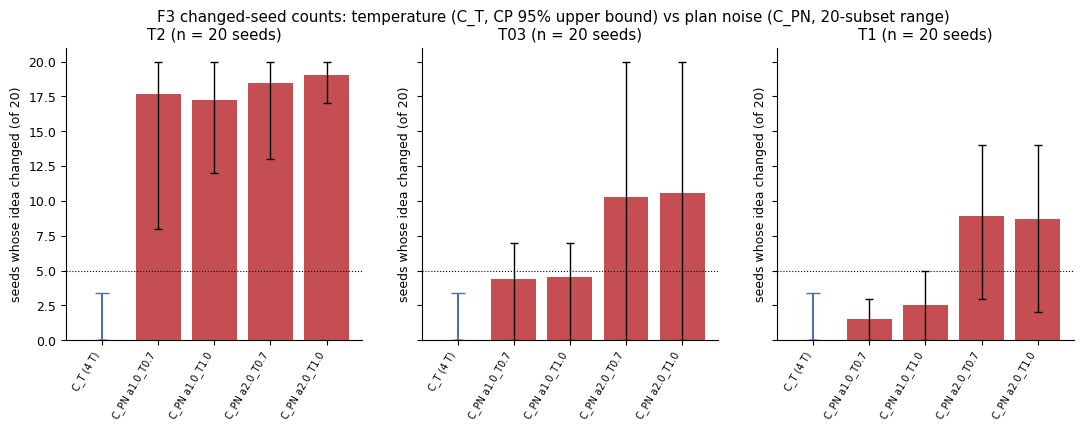

In [29]:
f3_counts(res)

**F1: coupling map.** One row is one token seed, with the same noise stream in every column. The columns are:
1. the 4 temperatures, then top-k 10 (between the two black lines);
2. the 6 plan-noise directions at α 1;
3. the same 6 directions at α 2, all at T 1.0.

Colour is the mechanism label, and hatching marks programs that failed the hidden tests. Read it row by row:
- The temperature columns keep one colour per seed.
- The plan-noise columns switch colour: on T2 from Dijkstra to Bellman-Ford/SPFA, on T03 from full sort to quickselect, on T1 from BFS to DFS.

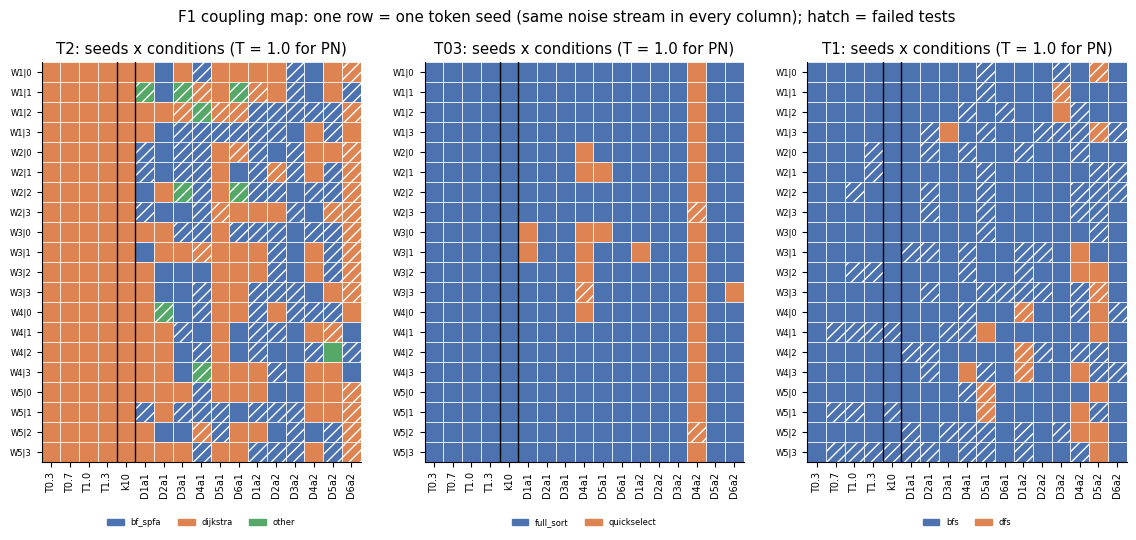

In [30]:
f1_coupling(idx)

**F2: ideas vs phrasings.** The y-axis is Hill-1 of the correct ideas (the effective number of algorithms), and the x-axis is phrasings per idea (PPI, θ 0.8).
- Blue arrows go along the temperatures. They move mostly sideways: more phrasings, the same idea.
- Dashed arrows go from NO-PN to plan noise. They move up: new ideas.

**F5: θ sweep.** The slope of log PPI on T at three Jaccard thresholds, per task and pooled. The pre-registered H-PHR needs every pooled slope > 0 with a CI excluding 0.

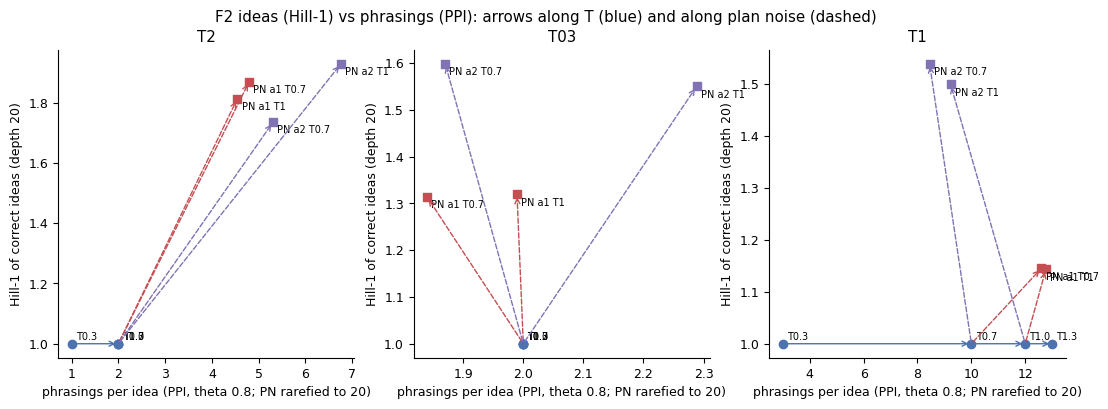

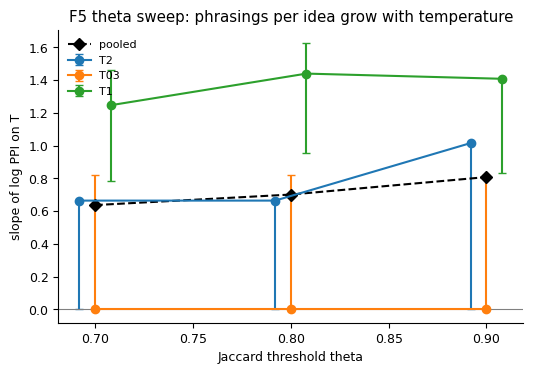

In [31]:
f2_hill_ppi(tab)
f5_theta(phr)

## Summary: computed vs reported

The key numbers of this run sit next to the values the artifact reports in `results/c1seed.json`, `phrasing.json` and `rederive.json`:
- **exact** rows (counts, means, slopes, the verdict) must agree at any Monte Carlo size;
- **MC** rows (p-values, CIs, rarefied Hill-1, test calibration) agree at the committed sizes used here, up to sampling error.

The plot shows both halves of the answer on the same token seeds:
- **Composition:** above the line are the temperature dials, where the default algorithm stays. Below it is plan noise, where the idea moves to Bellman-Ford/SPFA, quickselect or DFS.
- **PPI vs T:** temperature adds phrasings within an idea.

quantity                                                   this run                   reported                   kind
----------------------------------------------------------------------------------------------------------------------
C_T thinking off, 4 temperatures (T2 / T03 / T1)           0 / 0 / 0                  0 / 0 / 0                  exact
C_T thinking on, T2 (vLLM run, carried in metadata)        0                          0                          carried
C_PN alpha 1, T 1.0 (T2 / T03 / T1)                        17.250 / 4.550 / 2.500     17.250 / 4.550 / 2.500     exact
C_PN alpha 2, T 1.0 (T2 / T03 / T1)                        19.050 / 10.600 / 8.700    19.050 / 10.600 / 8.700    exact
C_PN correct-only, alpha 1, T 1.0 (T2 / T03 / T1)          10.250 / 4.050 / 1.450     10.250 / 4.050 / 1.450     exact
pooled x_s mean (T2 + T03, 40 seeds)                       0.545                      0.545                      exact
pooled x_s 95% bootstrap CI                    

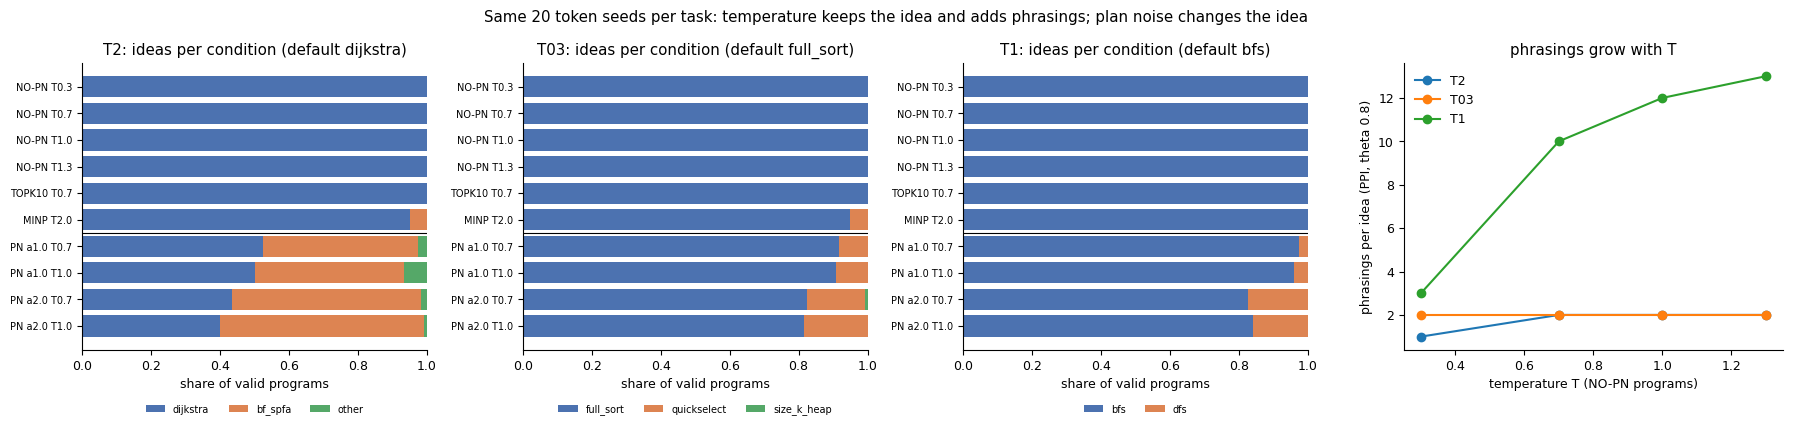

In [32]:
# ---- key numbers of this run next to the artifact's reported values ----
rep = data["metadata"]["reported"]
K1, K2 = "a1.0_T1.0", "a2.0_T1.0"
TH3 = ("0.7", "0.8", "0.9")


def _f(v: Any) -> str:
    if isinstance(v, bool) or v is None or isinstance(v, (int, str)):
        return str(v)
    if isinstance(v, float):
        return f"{v:.2e}" if 0 < abs(v) < 1e-3 else f"{v:.3f}"
    return " / ".join(_f(x) for x in v)


summary = [
    ("C_T thinking off, 4 temperatures (T2 / T03 / T1)", [res["A1_C_T_off"][t]["primary"]["C_T"] for t in TASKS],
     [rep["C_T_off"][t] for t in TASKS], "exact"),
    ("C_T thinking on, T2 (vLLM run, carried in metadata)", th["C_T_completed_all_4"]["C_T"],
     rep["decision_inputs"]["C_T"]["T2_on"], "carried"),
    ("C_PN alpha 1, T 1.0 (T2 / T03 / T1)", [res["A2_C_PN"][t][K1]["C_PN"] for t in TASKS],
     [rep["C_PN"][t][K1]["C_PN"] for t in TASKS], "exact"),
    ("C_PN alpha 2, T 1.0 (T2 / T03 / T1)", [res["A2_C_PN"][t][K2]["C_PN"] for t in TASKS],
     [rep["C_PN"][t][K2]["C_PN"] for t in TASKS], "exact"),
    ("C_PN correct-only, alpha 1, T 1.0 (T2 / T03 / T1)", [res["A2_C_PN"][t][K1]["C_PN_correct_only"] for t in TASKS],
     [rep["C_PN"][t][K1]["C_PN_correct_only"] for t in TASKS], "exact"),
    ("pooled x_s mean (T2 + T03, 40 seeds)", res["A3_x_contrast"]["pooled"]["mean_x"],
     rep["x_contrast_pooled"]["mean_x"], "exact"),
    ("pooled x_s 95% bootstrap CI", res["A3_x_contrast"]["pooled"]["boot95"], rep["x_contrast_pooled"]["boot95"], "MC"),
    ("pooled x_s sign-flip p (one-sided)", res["A3_x_contrast"]["pooled"]["sign_flip"]["p"],
     rep["x_contrast_pooled"]["sign_flip"]["p"], "MC"),
    ("within-seed permutation test p", res["A3_x_contrast"]["within_seed_permutation_test"]["p"],
     rep["within_seed_permutation_test"]["p"], "MC"),
    ("PPI slope on T, pooled (theta 0.7 / 0.8 / 0.9)", [phr["pooled"][k]["slope"] for k in TH3],
     [rep["phrasing_pooled"][k]["slope"] for k in TH3], "exact"),
    ("PPI slope 95% CI, lower end (theta 0.7 / 0.8 / 0.9)", [phr["pooled"][k]["ci95"][0] for k in TH3],
     [rep["phrasing_pooled"][k]["ci95"][0] for k in TH3], "MC"),
    ("Gumbel-max replicate: C_PN alpha 1, T 1.0 (T2 / T03)",
     [res["optional"]["iii_gumbel"][t]["C_PN"][K1]["C_PN"] for t in ("T2", "T03")],
     [rep["optional_iii_gumbel"][t]["C_PN"][K1] for t in ("T2", "T03")], "exact"),
    ("min-p T 2.0 as a 5th cell: C_T (T2 / T03 / T1)", [res["A1_sensitivities"][t]["with_MINP_as_5th"] for t in TASKS],
     [rep["C_T_sensitivities"][t]["with_MINP_as_5th"] for t in TASKS], "exact"),
    ("rarefied Hill-1, PN alpha 1, T 0.7 (T2 / T03 / T1)",
     [res["descriptive_expectations"][t]["PN_a1_T0.7_hill1_rarefied"] for t in TASKS],
     [rep["descriptive_expectations"][t]["PN_a1_T0.7_hill1_rarefied"] for t in TASKS], "MC"),
    ("verdict", res["verdict"]["verdict"], rep["verdict"]["verdict"], "exact"),
    ("rederive: mismatches / checks (here: no thinking/FP8 rows)", f"{red['mismatches']} / {len(red['checks'])}",
     f"{rep['rederive']['mismatches']} / {rep['rederive']['n_checks']}", "exact"),
    ("CPU tests: all pass", tests_res["all_pass"], rep["tests_cpu_all_pass"], "MC"),
]
print(f"{'quantity':<58} {'this run':<26} {'reported':<26} kind")
print("-" * 118)
for name, mine, theirs, kind in summary:
    print(f"{name:<58} {_f(mine):<26} {_f(theirs):<26} {kind}")
print("\nPN landings at alpha 1, T 1.0:", {t: res["descriptive_expectations"][t]["PN_landing_a1_T1.0"] for t in TASKS})

# ---- the answer in one picture: idea composition per condition (same seeds) and phrasings per idea vs T ----
conds = [cond_nopn(t) for t in TEMPS] + [TOPK_ARM, MINP_ARM] + \
    [f"PN_a{a:.1f}_T{fmt_t(t)}" for a in PN_ALPHAS for t in PN_TEMPS]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4), gridspec_kw={"width_ratios": [1, 1, 1, 1.1]})
for ax, task in zip(axes[:3], TASKS):
    cells = {r["condition"]: r for r in tab if r["task"] == task}
    labs = sorted({l for c in conds if c in cells for l in cells[c]["attempted"]}, key=lambda l: (l != DEFAULT4[task], l))
    left = np.zeros(len(conds))
    for i, l in enumerate(labs):
        share = np.array([cells[c]["attempted"].get(l, 0) / max(sum(cells[c]["attempted"].values()), 1)
                          if c in cells else 0.0 for c in conds])
        ax.barh(range(len(conds)), share, left=left, color=PALETTE[i % len(PALETTE)], label=l)
        left += share
    ax.set_yticks(range(len(conds)), [c.replace("NOPN_", "NO-PN ").replace("_", " ") for c in conds], fontsize=7)
    ax.invert_yaxis()
    ax.axhline(5.5, color="k", lw=0.8)
    ax.set_xlim(0, 1)
    ax.set_xlabel("share of valid programs")
    ax.set_title(f"{task}: ideas per condition (default {DEFAULT4[task]})")
    ax.legend(fontsize=7, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3)
ax = axes[3]
for task in TASKS:
    pb = phr["per_task"][task]["theta"]["0.8"]["ppi_by_T"]
    ax.plot([float(t) for t in pb], list(pb.values()), marker="o", label=task)
ax.set_xlabel("temperature T (NO-PN programs)")
ax.set_ylabel("phrasings per idea (PPI, theta 0.8)")
ax.set_title("phrasings grow with T")
ax.legend(frameon=False)
fig.suptitle("Same 20 token seeds per task: temperature keeps the idea and adds phrasings; plan noise changes the idea")
fig.tight_layout()
plt.show()